In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/attempt 1

/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/attempt 1


In [ ]:
!ls

strike1.ipynb


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/student_train.csv")
print(df.shape)


(43656, 2)


In [ ]:
df.head()

,time_idx,value
0,1,129
1,2,129
2,3,129
3,4,129
4,5,129


In [ ]:
import matplotlib.pyplot as plt


In [ ]:
df = df.set_index('time_idx')
df.index


Index([    1,     2,     3,     4,     5,     6,     7,     8,     9,    10,
       ...
       43647, 43648, 43649, 43650, 43651, 43652, 43653, 43654, 43655, 43656],
      dtype='int64', name='time_idx', length=43656)

In [ ]:
df.index = pd.to_datetime(df.index)

In [ ]:
import seaborn as sns

In [ ]:
df.describe()

,value
count,43656.000000
mean,98.173539
std,90.834754
min,0.000000
25%,30.000000
50%,73.000000
75%,136.000000
max,994.000000


<Axes: xlabel='time_idx'>

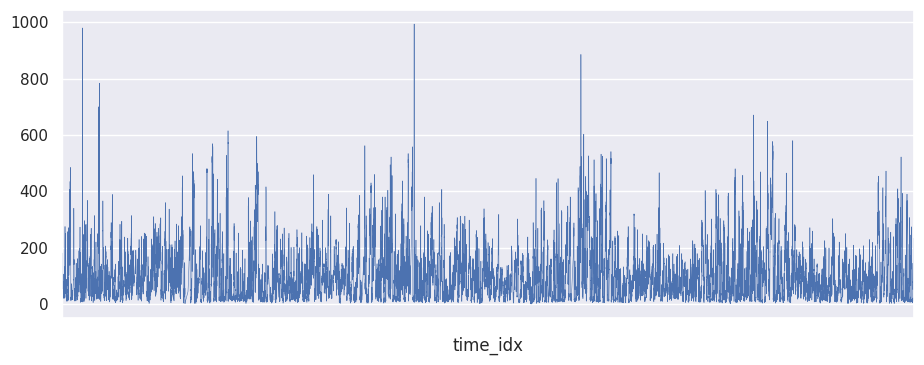

In [ ]:
sns.set(rc={'figure.figsize':(11, 4)})
df['value'].plot(linewidth=0.4)


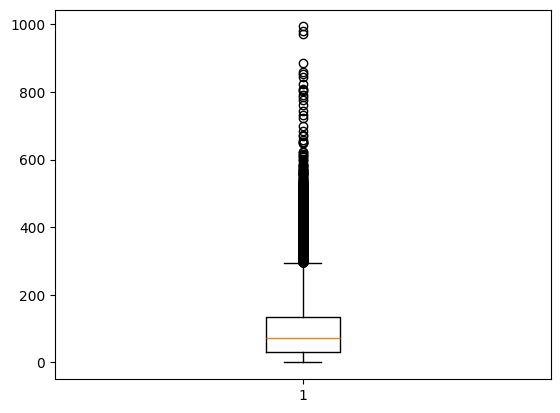

In [ ]:
plt.boxplot(df['value'])
plt.show()

In [ ]:
import numpy as np, pandas as pd

tr = pd.read_csv("/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/student_train.csv"); ex = pd.read_csv("/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/optional_external_data.csv")
y = tr["value"].to_numpy(float)
feats = [c for c in ex.columns if c != "time_idx"]
C = ex[feats].to_numpy(float)
print(len(y), len(ex), tr.time_idx.is_monotonic_increasing, np.isnan(y).sum(), np.isnan(C).sum())
print(pd.Series(y).describe(percentiles=[.5, .9, .99]).round(3))
print("fraction of zeros:", (y == 0).mean().round(4))

# Binary indicators: are they mutually exclusive?
binary = [f for f in feats if set(np.unique(ex[f])) <= {0, 1}]
print("binary:", binary)
if binary: print("row sums of binary cols:", ex[binary].sum(1).value_counts().to_dict())

# Periodic structure from the FFT of the training target
z = y - y.mean()
freq = np.fft.rfftfreq(len(z)); power = np.abs(np.fft.rfft(z)) ** 2
top = np.argsort(power[1:])[::-1][:12] + 1
print("top periods (samples), share of power:",
      [(round(1 / freq[i], 2), round(power[i] / power.sum(), 4)) for i in top])

# Autocorrelation at selected lags
def acf(x, lag): x = x - x.mean(); return float((x[:-lag] * x[lag:]).mean() / x.var())
print({l: round(acf(y, l), 3) for l in (1, 2, 6, 12, 24, 48, 168, 336)})

# Rolling-origin blocks: last 40 non-overlapping 168-step blocks of the training series
H = 168
ends = [len(y) - H * k for k in range(1, 41)][::-1]            # block = y[end-H:end]
def evaluate(forecast_fn):
    errs = []
    for e in ends:
        hist, true = y[:e - H], y[e - H:e]
        errs.append(forecast_fn(hist) - true)
    errs = np.concatenate(errs)
    return dict(RMSE=np.sqrt((errs ** 2).mean()).round(3), MAE=np.abs(errs).mean().round(3))
print("last value :", evaluate(lambda h: np.full(H, h[-1])))
print("mean       :", evaluate(lambda h: np.full(H, h.mean())))
for m in (24, 168):                                             # replace with periods from the FFT
    print(f"seasonal-naive m={m}:", evaluate(lambda h, m=m: np.tile(h[-m:], H // m + 1)[:H]))

# Do covariates relate to the target, and at which lead/lag? (training span only)
n = len(y)
for f_i, f in enumerate(feats):
    out = {k: round(float(np.corrcoef(y[max(0, -k):n - max(0, k)],
                                       C[:n][max(0, k):n - max(0, -k), f_i])[0, 1]), 3)
           for k in (-24, -1, 0, 1, 24)}                        # k>0: feature leads target
    print(f, out)

43656 43824 True 0 0
count    43656.000
mean        98.174
std         90.835
min          0.000
50%         73.000
90%        218.000
99%        418.000
max        994.000
dtype: float64
fraction of zeros: 0.0
binary: ['feature_G', 'feature_H', 'feature_I', 'feature_J']
row sums of binary cols: {1: 43824}
top periods (samples), share of power: [(np.float64(10914.0), np.float64(0.0121)), (np.float64(2910.4), np.float64(0.0105)), (np.float64(8731.2), np.float64(0.0096)), (np.float64(269.48), np.float64(0.0093)), (np.float64(24.0), np.float64(0.0089)), (np.float64(7276.0), np.float64(0.0086)), (np.float64(386.34), np.float64(0.0072)), (np.float64(183.43), np.float64(0.007)), (np.float64(187.36), np.float64(0.006)), (np.float64(532.39), np.float64(0.006)), (np.float64(207.89), np.float64(0.0059)), (np.float64(338.42), np.float64(0.0058))]
{1: 0.966, 2: 0.92, 6: 0.749, 12: 0.57, 24: 0.402, 48: 0.158, 168: 0.028, 336: 0.048}
last value : {'RMSE': np.float64(134.099), 'MAE': np.float64(86.45

# checks

In [ ]:

import numpy as np, pandas as pd
from scipy.signal import welch
from scipy.optimize import nnls
from scipy.stats import chi2
from scipy.ndimage import median_filter
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

H, NB = 168, 20
tr = pd.read_csv("/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/student_train.csv"); ex = pd.read_csv("/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/optional_external_data.csv")

y = pd.read_csv("/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/student_train.csv")["value"].to_numpy(float)
T = len(y)
SEL0, REP0 = T - 2 * NB * H, T - NB * H    # same split as task2_autoformer.py (non-debug)


RECENT = (24, 168, 720, 2160)


def candidates(h):
    """Every simple forecast for the next H steps, using only the history h."""
    out = {"global mean": np.full(H, h.mean()), "last value": np.full(H, h[-1])}
    for w in RECENT:
        out[f"mean last {w}"] = np.full(H, h[-w:].mean())
    phi = float(np.corrcoef(h[:-1], h[1:])[0, 1])          # how strongly one step predicts the next
    now = h[-3:].mean()
    steps = np.arange(1, H + 1)
    for tag, level in (("global", h.mean()), ("720", h[-720:].mean())):
        # start near the current value, then decay toward the long-run level at rate phi per step
        out[f"ACF shrink to {tag}"] = level + phi ** steps * (now - level)
    out["seasonal naive 24"] = np.tile(h[-24:], H // 24 + 1)[:H]
    return out


def collect(a0):
    """Forecasts and truth for NB consecutive 168-step blocks starting at index a0."""
    cands, truth = [], []
    for j in range(NB):
        a = a0 + H * j
        cands.append(candidates(y[:a]))                      # history strictly before the block
        truth.append(y[a:a + H])
    return {k: np.stack([c[k] for c in cands]) for k in cands[0]}, np.stack(truth)   # [NB, H]


BLEND = ["global mean", "mean last 168", "mean last 720", "ACF shrink to 720", "last value"]
BINS = np.array_split(np.arange(H), 7)                       # 7 bins of 24 horizon steps


def fit_blend(P, Y):
    """Non-negative least-squares weights per horizon bin, rescaled to sum to 1."""
    W = []
    for b in BINS:
        A = np.column_stack([P[k][:, b].ravel() for k in BLEND])
        w, _ = nnls(A, Y[:, b].ravel())
        W.append(w / w.sum() if w.sum() > 0 else np.full(len(BLEND), 1 / len(BLEND)))
    return np.array(W)                                       # [bins, candidates]


def apply_blend(P, W):
    out = np.zeros_like(P[BLEND[0]])
    for bi, b in enumerate(BINS):
        out[:, b] = sum(W[bi, i] * P[k][:, b] for i, k in enumerate(BLEND))
    return out


def summarise(P, Y, ref="global mean"):
    rows = []
    for k, f in P.items():
        e = f - Y
        diff = (e ** 2).mean(1) - ((P[ref] - Y) ** 2).mean(1)      # per-block MSE gap vs the mean forecast
        rows.append(dict(
            method=k, RMSE=np.sqrt((e ** 2).mean()), MAE=np.abs(e).mean(),
            **{f"RMSE h{b[0] + 1}-{b[-1] + 1}": np.sqrt((e[:, b] ** 2).mean()) for b in BINS},
            **{"MSE gap vs mean": diff.mean(), "std. error of gap": diff.std(ddof=1) / np.sqrt(len(diff))}))
    return pd.DataFrame(rows).sort_values("RMSE").round(3)


Ps, Ys = collect(SEL0)                                       # selection blocks: used to fit the blend
Pr, Yr = collect(REP0)                                       # report blocks: used for the numbers you quote
W = fit_blend(Ps, Ys)
Pr["blend (fit on selection blocks)"] = apply_blend(Pr, W)
table = summarise(Pr, Yr)
print("=== Baselines on the report blocks ===")
print(table.to_string(index=False))
table.to_csv("baselines_report_blocks.csv", index=False)
print("\nBlend weights per horizon bin; columns =", BLEND)
print(np.round(W, 2))


def welch_check(x, nperseg):
    x = x - x.mean()
    var = x.var()
    f, P = welch(x, fs=1.0, window="hann", nperseg=nperseg, noverlap=nperseg // 2, detrend="linear")
    f, P = f[1:], P[1:]                                      # drop the zero-frequency bin
    phi = float(np.corrcoef(x[:-1], x[1:])[0, 1])
    # one-sided spectrum of a plain short-memory (AR(1)) series with the same variance and phi
    null = 2 * var * (1 - phi ** 2) / (1 - 2 * phi * np.cos(2 * np.pi * f) + phi ** 2)
    ratio = P / null
    nseg = 1 + (len(x) - nperseg) // (nperseg // 2)
    thr = chi2.ppf(0.99, nseg) / nseg                        # rough 99% bound for the ratio under the null
    prom = ratio / median_filter(ratio, size=15, mode="nearest")   # how far a bin sticks out above its neighbours
    return f, P, null, ratio, prom, nseg, thr, phi


print("\n=== Welch spectrum vs a short-memory reference ===")
for nper in (1024, 2048, 4096):
    f, P, null, ratio, prom, nseg, thr, phi = welch_check(y, nper)
    per = 1 / f
    print(f"\nnperseg={nper}: {nseg} segments, phi={phi:.3f}, rough 99% ratio threshold={thr:.2f}")
    hit = np.flatnonzero((ratio > thr) & (prom > 3) & (per < nper / 2))
    top = hit[np.argsort(ratio[hit])[::-1]][:12]
    if len(top):
        print(pd.DataFrame({"period (steps)": per[top].round(2), "power / reference": ratio[top].round(2),
                            "prominence": prom[top].round(2)}).to_string(index=False))
    else:
        print("no frequency passes both the ratio and prominence screens")
    for p0 in (6, 8, 12, 24, 48, 168, 336):
        if p0 < nper / 2:
            i = int(np.argmin(np.abs(per - p0)))
            print(f"  period {p0}: power / reference = {ratio[i]:.2f} (prominence {prom[i]:.2f})")

# where does the variation live? (share of total power by cycle length, resolvable cycles only)
f, P, *_ = welch_check(y, 4096)
per = 1 / f
print("\nShare of variation by cycle length (nperseg=4096; very slow trends are partly removed by detrending):")
for lo, hi in [(720, 4096), (168, 720), (48, 168), (24, 48), (12, 24), (2, 12)]:
    m = (per >= lo) & (per < hi)
    print(f"  cycles of {lo}-{hi} steps: {100 * P[m].sum() / P.sum():5.1f}%")

f, P, null, ratio, prom, nseg, thr, phi = welch_check(y, 2048)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(1 / f, P, lw=0.8, label="Welch spectrum of the series")
ax.loglog(1 / f, null, "k--", lw=1.2, label=f"short-memory reference (phi={phi:.2f})")
for p0 in (24, 12, 8, 6):
    ax.axvline(p0, color="gray", ls=":", lw=0.7)
ax.set_xlabel("cycle length (steps)")
ax.set_ylabel("power (variance per unit frequency)")
ax.legend()
fig.savefig("welch_spectrum.png", dpi=150, bbox_inches="tight")
print("\nsaved welch_spectrum.png and baselines_report_blocks.csv")

=== Baselines on the report blocks ===
                         method    RMSE     MAE  RMSE h1-24  RMSE h25-48  RMSE h49-72  RMSE h73-96  RMSE h97-120  RMSE h121-144  RMSE h145-168  MSE gap vs mean  std. error of gap
blend (fit on selection blocks)  87.581  64.684      75.702       80.972      100.895       85.792        74.300         77.930        110.778        -1166.284            954.569
           ACF shrink to global  88.088  65.905      78.229       79.035       98.975       87.881        76.117         81.547        109.486        -1077.168           1004.377
              ACF shrink to 720  88.781  65.392      79.591       81.700      101.748       89.074        74.300         78.030        110.767         -954.522           1081.382
                    global mean  94.003  71.908     105.418       92.104      102.675       86.134        75.300         81.488        109.494            0.000              0.000
                  mean last 168  94.229  70.544     103.251       

In [ ]:



import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display
MODE = "full"          
DATA_DIR = "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data"          
THREADS = 2             # CPU threads (only matters on CPU)
OVERRIDES = dict(folds=1, seeds=[0], epochs=2)          

PRESETS = {
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=15, patience=4, bs=64, stride=2,
                 device="auto"),
}
SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} folds={FOLDS} blocks/fold={NB} seeds={SEEDS} epochs<={EPOCHS}")


# %% CELL 2: data and leakage-safe preprocessing
CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)


def geometry(k):
    """Rolling fold k (0 = latest): selection blocks, then report blocks, both NB x 168 steps."""
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0                     


def prep(fit_end):
    """Normalise with statistics from [0, fit_end) only, so nothing after it leaks."""
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    MU, SD = float(y[:fit_end].mean()), float(y[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (y - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)


# %% CELL 3: configuration and model
@dataclass(frozen=True)
class Cfg:
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 8                  # model width
    heads: int = 2
    el: int = 1                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept (strongest in Stage 1)
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12; Welch supports these two)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the Stage 1 ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 1            # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False


def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


def logit(p):
    return math.log(p / (1 - p))


class Decomp(nn.Module):
    def __init__(s, k):
        super().__init__()
        s.k = k

    def forward(s, x):                                       # x [B,T,D] -> (remainder, trend)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c = c.heads, c.c
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))            # learnable softmax temperature

    def forward(s, q, k, v):
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)        # [B,h,dh,L]
        # score(tau) = sum_t q_t k_{t-tau}: same convention as the Task 1 delay scores
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L                               # v[t - tau]
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)             # tied: same module, counted once in P
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


class Feats(nn.Module):
    """Side inputs: selected covariates, a learned category embedding, and Fourier harmonics."""
    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)                                # exact phase on the index
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


class Baseline(nn.Module):
    """level + phi^h * (now - level): a learnable mean-reversion forecast. 3 parameters (4 with `slow`).

    These numbers are registered as parameters on purpose, so they are counted in P.
    """
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))        # sigmoid -> memory per step
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))    # sigmoid -> smoothing rate of "now"
        s.level = nn.Parameter(torch.zeros(()))                  # long-run level (standardised units)
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))           # sigmoid -> weight on the slow level
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)                            # [B,1]
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)         # [B,H]


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))                 # fixed, no parameters
        s.base = Baseline(c) if c.residual else None
        if c.residual:                                                           # start exactly at the baseline
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)                                                     # [B,L,1]
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)                  # trend starts at zero
        else:                                                                    # standard Autoformer trend init
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


# %% CELL 4: batching, training, evaluation, arms, summary
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()                  # mean of the last W_slow steps before the window end
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


def blocks(a0, c):
    """Window starts for NB consecutive non-overlapping 168-step targets beginning at a0."""
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)


@torch.no_grad()
def evaluate(m, starts, c):
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return torch.cat(P) * SD + MU, torch.cat(Tg) * SD + MU        # original units


def rmse_t(p, t):
    return (p - t).pow(2).mean().sqrt().item()


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def fit(c, seed, epochs, val=None):
    """Train with AdamW + cosine decay. With `val`, stop early (patience) and keep the best checkpoint."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = Net(c).to(DEV)
    base_params = list(m.base.parameters()) if m.base is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:                                                # no weight decay on the baseline's few numbers
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1                                  # every target ends before FIT_END
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))                  # different window subset each epoch
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run


# Arms: each one is an RMSE-vs-P point.
BASE = Cfg()
ARMS = {
    "plain":         replace(BASE, residual=False, cov="none", fourier=0),   # tiny plain Autoformer
    "base":          replace(BASE, cov="none", fourier=0),                   # + learnable baseline residual
    "dec":           replace(BASE, cov="dec", fourier=0),                    # + future-known covariates
    "both":          replace(BASE, cov="both", fourier=0),                   # + past covariates in the encoder
    "dec+f2":        replace(BASE, cov="dec", fourier=2),                    # + 2 Fourier harmonics (recommended)
    "dec+f2+slow":   replace(BASE, cov="dec", fourier=2, slow=True),         # + slow level (weak evidence)
    "dec+f2 d16":    replace(BASE, cov="dec", fourier=2, d=16),              # wider
    "dec+f2 untied": replace(BASE, cov="dec", fourier=2, tie_dec=False, share_qk=False, proj_out=True,
                             ff_mult=2, bias=True),                          # no parameter savings
}


def base_forecasts(h):
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m), "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m)}


def run_all(names):
    E = {a: {s: [] for s in SEEDS} for a in names}
    BE = {"global mean": [], "ACF shrink": []}
    info = {a: dict(P=None, best=[], run=[], secs=0.0) for a in names}
    for k in range(FOLDS):
        sel0, rep0 = geometry(k)
        prep(sel0)
        origins = [rep0 + H * j for j in range(NB)]
        for name in BE:
            BE[name].append(np.stack([base_forecasts(y[:a])[name] - y[a:a + H] for a in origins]))
        for a in names:
            c = ARMS[a]
            sel, rep = blocks(sel0, c), blocks(rep0, c)
            t0 = time.time()
            for sd in SEEDS:
                m, best_ep, run = fit(c, sd, EPOCHS, val=sel)
                p, t = evaluate(m, rep, c)
                E[a][sd].append((p - t).cpu().numpy())
                info[a]["P"] = count(m)
                info[a]["best"].append(best_ep)
                info[a]["run"].append(run)
            info[a]["secs"] += time.time() - t0
            print(f"fold {k} | {a:14s} | P={info[a]['P']:5d} | {time.time() - t0:6.1f}s for {len(SEEDS)} seeds",
                  flush=True)
    return E, BE, info


def gap(mse_blocks, ref):
    d = mse_blocks - ref
    return float(d.mean()), float(d.std(ddof=1) / np.sqrt(len(d)))


def summarise(names, E, BE, info):
    base_err = {k: np.concatenate(v) for k, v in BE.items()}
    ref = (base_err["ACF shrink"] ** 2).mean(1)
    rows = []
    for k, e in base_err.items():
        g, se = gap((e ** 2).mean(1), ref)
        rows.append(dict(arm=f"baseline: {k}", P=0, RMSE=np.sqrt((e ** 2).mean()), RMSE_sd=np.nan,
                         MSE=(e ** 2).mean(), MAE=np.abs(e).mean(), gap_vs_ACF=g, gap_SE=se,
                         epochs_run=np.nan, best_epoch=np.nan))
    for a in names:
        per = [np.concatenate(E[a][s]) for s in SEEDS]
        rm = [np.sqrt((e ** 2).mean()) for e in per]
        g, se = gap(np.mean([(e ** 2).mean(1) for e in per], 0), ref)             # seed-averaged per-block MSE
        rows.append(dict(arm=a, P=info[a]["P"], RMSE=np.mean(rm),
                         RMSE_sd=np.std(rm, ddof=1) if len(rm) > 1 else np.nan,
                         MSE=np.mean([(e ** 2).mean() for e in per]), MAE=np.mean([np.abs(e).mean() for e in per]),
                         gap_vs_ACF=g, gap_SE=se, epochs_run=np.mean(info[a]["run"]),
                         best_epoch=np.mean(info[a]["best"])))
    return pd.DataFrame(rows).round(3)


def final_forecast(c, seeds, epochs):
    """Refit on all T points for a fixed number of epochs and forecast time_idx T+1 .. T+168."""
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs, val=None)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)                      # the target is non-negative
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}.")
    print("E to declare = the epochs of the early-stopped run(s) that chose the epoch count + these refit epochs. "
          "Confirm with the TAs whether ablation runs must also be counted.")
    print("\nPaste this into the leaderboard:\n" + txt)
    return out


# %% CELL 5: parameter counts and shape smoke test (fast; run this before the experiments)
prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = Net(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:14s} {count(m):6d}")


# %% CELL 6: run the experiments (the slow cell)
ARMS_TO_RUN = ["dec+f2"]     # None = all arms; or e.g. ["plain", "base", "dec+f2"]
names = list(ARMS) if ARMS_TO_RUN is None else ARMS_TO_RUN
E, BE, info = run_all(names)
df = summarise(names, E, BE, info)
print("\nReport blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline")
display(df.sort_values("P"))
df.to_csv("task2_results.csv", index=False)


# %% CELL 7: final 168-step forecast (run only after you have chosen an arm and an epoch count)
FINAL_ARM = "dec+f2"
FINAL_EPOCHS = 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)

mode=full device=cuda folds=1 blocks/fold=20 seeds=[0] epochs<=2
T = 43656 | N = 43824
parameter counts (the script's own count is the one to declare):
  plain             596
  base              599
  dec               639
  both              671
  dec+f2            703
  dec+f2+slow       704
  dec+f2 d16       2415
  dec+f2 untied    1584
fold 0 | dec+f2         | P=  703 |    8.0s for 1 seeds

Report blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline


,arm,P,RMSE,RMSE_sd,MSE,MAE,gap_vs_ACF,gap_SE,epochs_run,best_epoch
0,baseline: global mean,0,94.003,NaN,8836.657,71.908,1077.168,1004.377,NaN,NaN
1,baseline: ACF shrink,0,88.088,NaN,7759.490,65.905,0.000,0.000,NaN,NaN
2,dec+f2,703,81.469,NaN,6637.261,63.561,-1122.229,618.939,2.0,1.0


saved forecast_168.txt (168 values, first=0.00, last=0.00)
declare P = 703 (sum over 1 model(s)); refit epochs = 10.
E to declare = the epochs of the early-stopped run(s) that chose the epoch count + these refit epochs. Confirm with the TAs whether ablation runs must also be counted.

Paste this into the leaderboard:
0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4899,3.9312,5.1188,9.8466,15.6429,29.2107,32.0147,36.9180,46.0058,57.3467,79.2080,96.7692,128.5838,129.8668,138.5663,134.1067,160.7821,164.9446,168.7637,177.6136,182.8647,179.0137,173.9721,168.3650,165.2310,152.9462,169.3679,168.9743,175.4773,173.1614,178.4533,182.4859,185.4833,184.4144,182.1347,188.0686,176.9343,182.9354,186.5638,189.7920,186.7488,178.7367,177.0663,173.8998,165.8441,161.4918,153.5214,154.3806,154.6042,146.9621,157.8418,157.3091,155.7440,159.6425,158.7529,157.7376,155.7930,160.1143,160.4109,170.9464,180.6551,183.4718,184.8293,198.3163,186.8115,183.1330,183.7992,179.4331,158.6880,141.6200,126.4159,115.3444,

In [ ]:
%cd /content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/attempt 1

/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/attempt 1


#tiny autoformer full

In [ ]:
# Task 2: tiny Autoformer that learns a residual on top of a learnable mean-reversion baseline.
# UNTESTED DRAFT in this cell form. Paste each block below into its own Colab cell, in order.
# The "# %% CELL n" lines are only markers; you can leave them in.


In [ ]:

# %% CELL 1: settings. Edit MODE here, then re-run this cell and every cell below it.
import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display
MODE = "full"          # "debug" = CPU smoke test on a small slice; "full" = all data (use a GPU runtime)
DATA_DIR = "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data"          # folder that holds student_train.csv and optional_external_data.csv
THREADS = 2             # CPU threads (only matters on CPU)
OVERRIDES = {}          # e.g. dict(folds=1, seeds=[0], epochs=5) to time a single run in full mode

PRESETS = {
    # debug: first 3,500 rows, 1 fold of 3 blocks, 2 seeds, 2 epochs, CPU
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    # full: all data, 3 rolling folds x 20 blocks, 5 seeds, up to 15 epochs, GPU if available
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=10, patience=4, bs=64, stride=2,
                 device="auto"),
}

In [ ]:


SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} folds={FOLDS} blocks/fold={NB} seeds={SEEDS} epochs<={EPOCHS}")


mode=full device=cuda folds=3 blocks/fold=20 seeds=[0, 1, 2, 3, 4] epochs<=10


In [ ]:


# %% CELL 2: data and leakage-safe preprocessing
CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)



In [ ]:

def geometry(k):
    """Rolling fold k (0 = latest): selection blocks, then report blocks, both NB x 168 steps."""
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0                     # (sel0, rep0); training uses targets before sel0



In [ ]:

def prep(fit_end):
    """Normalise with statistics from [0, fit_end) only, so nothing after it leaks."""
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    MU, SD = float(y[:fit_end].mean()), float(y[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (y - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)


T = 43656 | N = 43824


In [ ]:


# %% CELL 3: configuration and model
@dataclass(frozen=True)
class Cfg:
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 8                  # model width
    heads: int = 2
    el: int = 1                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept (strongest in Stage 1)
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12; Welch supports these two)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the Stage 1 ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 1            # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False



In [ ]:

def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


In [ ]:


def logit(p):
    return math.log(p / (1 - p))


class Decomp(nn.Module):
    def __init__(s, k):
        super().__init__()
        s.k = k

    def forward(s, x):                                       # x [B,T,D] -> (remainder, trend)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c = c.heads, c.c
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))            # learnable softmax temperature

    def forward(s, q, k, v):
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)        # [B,h,dh,L]
        # score(tau) = sum_t q_t k_{t-tau}: same convention as the Task 1 delay scores
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L                               # v[t - tau]
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)             # tied: same module, counted once in P
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


class Feats(nn.Module):
    """Side inputs: selected covariates, a learned category embedding, and Fourier harmonics."""
    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)                                # exact phase on the index
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


class Baseline(nn.Module):
    """level + phi^h * (now - level): a learnable mean-reversion forecast. 3 parameters (4 with `slow`).

    These numbers are registered as parameters on purpose, so they are counted in P.
    """
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))        # sigmoid -> memory per step
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))    # sigmoid -> smoothing rate of "now"
        s.level = nn.Parameter(torch.zeros(()))                  # long-run level (standardised units)
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))           # sigmoid -> weight on the slow level
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)                            # [B,1]
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)         # [B,H]


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))                 # fixed, no parameters
        s.base = Baseline(c) if c.residual else None
        if c.residual:                                                           # start exactly at the baseline
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)                                                     # [B,L,1]
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)                  # trend starts at zero
        else:                                                                    # standard Autoformer trend init
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


# %% CELL 4: batching, training, evaluation, arms, summary
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()                  # mean of the last W_slow steps before the window end
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


def blocks(a0, c):
    """Window starts for NB consecutive non-overlapping 168-step targets beginning at a0."""
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)


@torch.no_grad()
def evaluate(m, starts, c):
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return torch.cat(P) * SD + MU, torch.cat(Tg) * SD + MU        # original units


def rmse_t(p, t):
    return (p - t).pow(2).mean().sqrt().item()


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def fit(c, seed, epochs, val=None):
    """Train with AdamW + cosine decay. With `val`, stop early (patience) and keep the best checkpoint."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = Net(c).to(DEV)
    base_params = list(m.base.parameters()) if m.base is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:                                                # no weight decay on the baseline's few numbers
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1                                  # every target ends before FIT_END
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))                  # different window subset each epoch
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run


# Arms: each one is an RMSE-vs-P point.
BASE = Cfg()
ARMS = {
    "plain":         replace(BASE, residual=False, cov="none", fourier=0),   # tiny plain Autoformer
    "base":          replace(BASE, cov="none", fourier=0),                   # + learnable baseline residual
    "dec":           replace(BASE, cov="dec", fourier=0),                    # + future-known covariates
    "both":          replace(BASE, cov="both", fourier=0),                   # + past covariates in the encoder
    "dec+f2":        replace(BASE, cov="dec", fourier=2),                    # + 2 Fourier harmonics (recommended)
    "dec+f2+slow":   replace(BASE, cov="dec", fourier=2, slow=True),         # + slow level (weak evidence)
    "dec+f2 d16":    replace(BASE, cov="dec", fourier=2, d=16),              # wider
    "dec+f2 untied": replace(BASE, cov="dec", fourier=2, tie_dec=False, share_qk=False, proj_out=True,
                             ff_mult=2, bias=True),                          # no parameter savings
}


def base_forecasts(h):
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m), "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m)}


def run_all(names):
    E = {a: {s: [] for s in SEEDS} for a in names}
    BE = {"global mean": [], "ACF shrink": []}
    info = {a: dict(P=None, best=[], run=[], secs=0.0) for a in names}
    for k in range(FOLDS):
        sel0, rep0 = geometry(k)
        prep(sel0)
        origins = [rep0 + H * j for j in range(NB)]
        for name in BE:
            BE[name].append(np.stack([base_forecasts(y[:a])[name] - y[a:a + H] for a in origins]))
        for a in names:
            c = ARMS[a]
            sel, rep = blocks(sel0, c), blocks(rep0, c)
            t0 = time.time()
            for sd in SEEDS:
                m, best_ep, run = fit(c, sd, EPOCHS, val=sel)
                p, t = evaluate(m, rep, c)
                E[a][sd].append((p - t).cpu().numpy())
                info[a]["P"] = count(m)
                info[a]["best"].append(best_ep)
                info[a]["run"].append(run)
            info[a]["secs"] += time.time() - t0
            print(f"fold {k} | {a:14s} | P={info[a]['P']:5d} | {time.time() - t0:6.1f}s for {len(SEEDS)} seeds",
                  flush=True)
    return E, BE, info


def gap(mse_blocks, ref):
    d = mse_blocks - ref
    return float(d.mean()), float(d.std(ddof=1) / np.sqrt(len(d)))


def summarise(names, E, BE, info):
    base_err = {k: np.concatenate(v) for k, v in BE.items()}
    ref = (base_err["ACF shrink"] ** 2).mean(1)
    rows = []
    for k, e in base_err.items():
        g, se = gap((e ** 2).mean(1), ref)
        rows.append(dict(arm=f"baseline: {k}", P=0, RMSE=np.sqrt((e ** 2).mean()), RMSE_sd=np.nan,
                         MSE=(e ** 2).mean(), MAE=np.abs(e).mean(), gap_vs_ACF=g, gap_SE=se,
                         epochs_run=np.nan, best_epoch=np.nan))
    for a in names:
        per = [np.concatenate(E[a][s]) for s in SEEDS]
        rm = [np.sqrt((e ** 2).mean()) for e in per]
        g, se = gap(np.mean([(e ** 2).mean(1) for e in per], 0), ref)             # seed-averaged per-block MSE
        rows.append(dict(arm=a, P=info[a]["P"], RMSE=np.mean(rm),
                         RMSE_sd=np.std(rm, ddof=1) if len(rm) > 1 else np.nan,
                         MSE=np.mean([(e ** 2).mean() for e in per]), MAE=np.mean([np.abs(e).mean() for e in per]),
                         gap_vs_ACF=g, gap_SE=se, epochs_run=np.mean(info[a]["run"]),
                         best_epoch=np.mean(info[a]["best"])))
    return pd.DataFrame(rows).round(3)


def final_forecast(c, seeds, epochs):
    """Refit on all T points for a fixed number of epochs and forecast time_idx T+1 .. T+168."""
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs, val=None)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)                      # the target is non-negative
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}.")
    print("E to declare = the epochs of the early-stopped run(s) that chose the epoch count + these refit epochs. "
          "Confirm with the TAs whether ablation runs must also be counted.")
    print("\nPaste this into the leaderboard:\n" + txt)
    return out



In [ ]:

# %% CELL 5: parameter counts and shape smoke test (fast; run this before the experiments)
prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = Net(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:14s} {count(m):6d}")



parameter counts (the script's own count is the one to declare):
  plain             596
  base              599
  dec               639
  both              671
  dec+f2            703
  dec+f2+slow       704
  dec+f2 d16       2415
  dec+f2 untied    1584


In [ ]:

# %% CELL 6: run the experiments (the slow cell)
ARMS_TO_RUN = ["dec+f2"]     # None = all arms; or e.g. ["plain", "base", "dec+f2"]
names = list(ARMS) if ARMS_TO_RUN is None else ARMS_TO_RUN
E, BE, info = run_all(names)
df = summarise(names, E, BE, info)
print("\nReport blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline")
display(df.sort_values("P"))
df.to_csv("task2_results.csv", index=False)


fold 0 | dec+f2         | P=  703 |  170.8s for 5 seeds
fold 1 | dec+f2         | P=  703 |  175.6s for 5 seeds
fold 2 | dec+f2         | P=  703 |  162.3s for 5 seeds

Report blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline


,arm,P,RMSE,RMSE_sd,MSE,MAE,gap_vs_ACF,gap_SE,epochs_run,best_epoch
0,baseline: global mean,0,94.363,NaN,8904.351,70.677,1000.229,463.311,NaN,NaN
1,baseline: ACF shrink,0,88.905,NaN,7904.122,66.283,0.000,0.000,NaN,NaN
2,dec+f2,703,73.040,3.79,5346.339,53.772,-2557.783,528.794,9.067,6.533


In [ ]:
  print("last 12 observed:", np.round(y[-12:], 1))
  print("future covariates, first 5 steps:\n", np.round(C[T:T+5], 2), cat_id[T:T+5])

last 12 observed: [12. 14. 14. 12. 16. 16. 12. 20. 23. 16. 17. 18.]
future covariates, first 5 steps:
 [[-1.400e+01  2.000e+00  1.033e+03  7.555e+01  0.000e+00  0.000e+00]
 [-1.400e+01  1.000e+00  1.033e+03  7.957e+01  0.000e+00  0.000e+00]
 [-1.400e+01  1.000e+00  1.034e+03  8.449e+01  0.000e+00  0.000e+00]
 [-1.300e+01 -3.000e+00  1.034e+03  8.851e+01  0.000e+00  0.000e+00]
 [-1.400e+01 -3.000e+00  1.034e+03  9.164e+01  0.000e+00  0.000e+00]] [1 1 1 1 1]


In [ ]:


# %% CELL 7: final 168-step forecast (run only after you have chosen an arm and an epoch count)
FINAL_ARM = "dec+f2"
FINAL_EPOCHS = 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)

saved forecast_168.txt (168 values, first=0.00, last=1.26)
declare P = 703 (sum over 1 model(s)); refit epochs = 10.
E to declare = the epochs of the early-stopped run(s) that chose the epoch count + these refit epochs. Confirm with the TAs whether ablation runs must also be counted.

Paste this into the leaderboard:
0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.3691,8.5172,22.1221,26.5388,29.8405,40.6878,52.1375,74.1581,89.4849,121.3513,124.7625,133.3262,129.4879,154.7735,160.3294,163.1746,172.5795,175.8393,175.0143,167.3649,163.6404,162.5510,153.2550,170.7403,169.2374,178.4219,176.7424,184.1101,187.4624,190.4619,188.6724,187.3526,192.4631,184.0074,189.7944,192.3977,194.2778,189.7086,180.8699,179.4042,175.4349,166.6856,162.8682,155.9026,157.3470,157.4583,152.9111,164.6426,163.7739,159.9680,163.5159,163.0479,161.7903,159.8244,164.0196,164.5010,175.1729,185.0261,188.8753,190.6710,202.4472,190.4954,185.1850,186.4202,181.6815,162.3043,146.3201,131.6278,123.0125,1

In [ ]:

# %% CELL 6: run the experiments (the slow cell)
ARMS_TO_RUN = ["plain", "base", "dec+f2", "dec+f2 d16", "dec+f2+slow", "dec+f2 untied"]     # None = all arms; or e.g. ["plain", "base", "dec+f2"]
names = list(ARMS) if ARMS_TO_RUN is None else ARMS_TO_RUN
E, BE, info = run_all(names)
df = summarise(names, E, BE, info)
print("\nReport blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline")
display(df.sort_values("P"))
df.to_csv("task2_results.csv", index=False)

fold 0 | plain          | P=  596 |  101.3s for 5 seeds
fold 0 | base           | P=  599 |  143.9s for 5 seeds
fold 0 | dec+f2         | P=  703 |  187.2s for 5 seeds
fold 0 | dec+f2 d16     | P= 2415 |  149.8s for 5 seeds
fold 0 | dec+f2+slow    | P=  704 |  170.7s for 5 seeds
fold 0 | dec+f2 untied  | P= 1584 |  155.7s for 5 seeds
fold 1 | plain          | P=  596 |   96.1s for 5 seeds
fold 1 | base           | P=  599 |  159.6s for 5 seeds
fold 1 | dec+f2         | P=  703 |  185.2s for 5 seeds
fold 1 | dec+f2 d16     | P= 2415 |  178.2s for 5 seeds
fold 1 | dec+f2+slow    | P=  704 |  188.1s for 5 seeds
fold 1 | dec+f2 untied  | P= 1584 |  192.2s for 5 seeds
fold 2 | plain          | P=  596 |   73.8s for 5 seeds
fold 2 | base           | P=  599 |  131.6s for 5 seeds
fold 2 | dec+f2         | P=  703 |  152.1s for 5 seeds
fold 2 | dec+f2 d16     | P= 2415 |  112.9s for 5 seeds
fold 2 | dec+f2+slow    | P=  704 |  152.2s for 5 seeds
fold 2 | dec+f2 untied  | P= 1584 |  151.9s for 

,arm,P,RMSE,RMSE_sd,MSE,MAE,gap_vs_ACF,gap_SE,epochs_run,best_epoch
0,baseline: global mean,0,94.363,NaN,8904.351,70.677,1000.229,463.311,NaN,NaN
1,baseline: ACF shrink,0,88.905,NaN,7904.122,66.283,0.000,0.000,NaN,NaN
2,plain,596,106.388,1.329,11319.719,77.945,3415.596,1406.641,5.600,1.600
3,base,599,88.894,0.142,7902.199,66.313,-1.923,38.431,8.267,4.600
4,dec+f2,703,72.711,3.613,5297.403,53.264,-2606.719,516.782,9.467,6.667
6,dec+f2+slow,704,72.577,3.307,5276.127,53.032,-2627.995,519.387,9.067,6.533
7,dec+f2 untied,1584,68.902,1.256,4748.688,50.243,-3155.435,544.785,8.267,4.933
5,dec+f2 d16,2415,72.685,4.528,5299.526,53.755,-2604.597,545.987,7.933,5.000


In [ ]:


# %% CELL 7: final 168-step forecast (run only after you have chosen an arm and an epoch count)
FINAL_ARM = "dec+f2"
FINAL_EPOCHS = 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)

saved forecast_168.txt (168 values, first=0.00, last=0.83)
declare P = 703 (sum over 1 model(s)); refit epochs = 10.
E to declare = the epochs of the early-stopped run(s) that chose the epoch count + these refit epochs. Confirm with the TAs whether ablation runs must also be counted.

Paste this into the leaderboard:
0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.1616,3.6011,9.6446,23.2878,27.8876,31.4462,42.4262,54.0337,76.4891,91.9632,124.0054,127.1286,135.9661,131.7421,157.0049,162.7481,165.4079,174.7299,178.0349,177.4965,169.5914,165.9540,165.0219,155.3248,173.0566,171.4941,180.1883,178.6963,186.3576,189.8842,193.0464,191.3875,190.1329,194.8245,186.3145,191.7228,194.6392,196.2898,191.4603,182.6381,180.7947,176.6665,168.0678,164.4101,157.4969,158.7924,158.7320,154.1398,165.9892,165.0862,161.3702,165.0945,165.0006,163.9654,162.0416,166.2262,166.5437,177.5323,187.4267,191.3116,192.9442,204.5744,192.2588,186.9504,188.3935,183.5102,164.0996,147.9797,133.1466,124.2463,1

# v2


mode=full device=cuda target=raw folds=3 blocks/fold=20 seeds=[0, 1, 2] epochs<=15
T = 43656 | N = 43824
parameter counts (the script's own count is the one to declare):
  plain              596
  base               599
  dec                639
  both               671
  dec+f2             703
  dec+f2+slow        704
  dec+f2 d16        2415
  dec+f2 untied     1584
  base+f2            663
  dec+f2 noAC        445
  dec+f2 noDecomp    703
  linhead             20
  dlinear          32592
  dec+f2 noband      703
  dec+f2 lag2        703
  dec+f2 lag16       703
  dec+f2 L48         703
  dec+f2 L168        703
  dec+f2 k13         703
  dec+f2 k49         703
design region = first 30216 steps; 300 random origins x 168 future steps


,pearson,spearman
A,0.217,0.320
B,-0.046,0.037
C,-0.108,-0.174
D,-0.260,-0.368
E,0.054,0.062
F,-0.049,0.005


category (G-J) eta^2 vs baseline residual: 0.074
top-2 by |spearman|: ['D', 'A'] | current Cfg.cont: ('A', 'D')


,epochs,sel_RMSE,sd
0,6,54.857,0.743
1,10,54.107,1.708


FIXED_E = 10 (applied to every arm below; set FIXED_E = None to use early stopping instead)
fold 0 | base+f2         | P=  663 |  120.7s for 3 seeds
fold 0 | dec+f2          | P=  703 |  124.5s for 3 seeds
fold 0 | dec+f2 noAC     | P=  445 |   62.0s for 3 seeds
fold 0 | linhead         | P=   20 |   33.7s for 3 seeds
fold 1 | base+f2         | P=  663 |  109.3s for 3 seeds
fold 1 | dec+f2          | P=  703 |  113.0s for 3 seeds
fold 1 | dec+f2 noAC     | P=  445 |   56.0s for 3 seeds
fold 1 | linhead         | P=   20 |   30.4s for 3 seeds
fold 2 | base+f2         | P=  663 |   98.4s for 3 seeds
fold 2 | dec+f2          | P=  703 |  101.5s for 3 seeds
fold 2 | dec+f2 noAC     | P=  445 |   51.1s for 3 seeds
fold 2 | linhead         | P=   20 |   27.4s for 3 seeds

Report blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline (CI = moving-block bootstrap over blocks)


,arm,P,RMSE,RMSE_sd,MSE,MAE,gap_vs_ACF,gap_SE,gap_CI_lo,gap_CI_hi,epochs_run,best_epoch
0,baseline: global mean,0,94.363,NaN,8904.351,70.677,1000.229,463.311,256.709,1921.697,NaN,NaN
1,baseline: ACF shrink,0,88.905,NaN,7904.122,66.283,0.000,0.000,0.000,0.000,NaN,NaN
2,baseline: seasonal naive 24,0,132.591,NaN,17580.267,92.417,9676.145,2576.850,5269.558,15451.385,NaN,NaN
3,baseline: seasonal naive 168,0,130.830,NaN,17116.587,92.818,9212.464,1623.257,6372.635,12532.122,NaN,NaN
7,linhead,20,84.638,0.026,7163.675,62.118,-740.447,192.961,-1296.451,-224.074,10.0,10.0
6,dec+f2 noAC,445,74.110,1.504,5493.771,54.011,-2410.351,509.470,-3672.165,-1207.027,10.0,10.0
4,base+f2,663,87.877,0.054,7722.289,65.918,-181.834,92.331,-385.693,0.157,10.0,10.0
5,dec+f2,703,68.632,1.544,4711.953,50.100,-3192.170,594.831,-4719.635,-1867.164,10.0,10.0



Per-fold RMSE (seed-averaged)


,arm,fold0,fold1,fold2
0,baseline: global mean,94.00,66.82,115.81
1,baseline: ACF shrink,88.09,63.09,109.42
2,baseline: seasonal naive 24,130.48,91.42,165.41
3,baseline: seasonal naive 168,131.25,94.35,158.81
4,base+f2,88.13,62.09,107.45
5,dec+f2,68.14,52.55,82.00
6,dec+f2 noAC,72.84,58.35,88.11
7,linhead,83.56,63.82,102.15


saved forecast_168.txt (168 values, first=0.00, last=37.76, zeros=17)
declare P = 703 (sum over 1 model(s)); refit epochs = 10.
E to declare = the epochs used to choose the epoch count (CELL 6a, if you count them) + these refit epochs. Confirm with the TAs whether ablation runs must also be counted.

Paste this into the leaderboard:
0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.5566,11.9058,30.7526,45.1565,73.2810,80.1523,89.5926,82.0005,101.0222,109.7379,125.6828,139.3806,144.1304,145.9500,138.4645,129.2555,127.5415,123.1241,139.1881,139.4017,153.4594,156.9135,168.4074,176.8408,183.1855,187.9434,187.8162,187.3756,182.0965,185.5570,182.2509,186.1913,186.1167,177.0274,177.9847,175.4924,167.4789,161.8566,154.7241,155.1547,158.8107,152.0915,164.2592,162.1484,157.5959,156.9307,160.3342,160.2631,156.5675,155.9769,152.1237,156.9362,164.8996,173.3952,181.7861,200.0489,190.9182,188.9662,189.3327,188.8222,173.2783,157.4576,140.3694,12

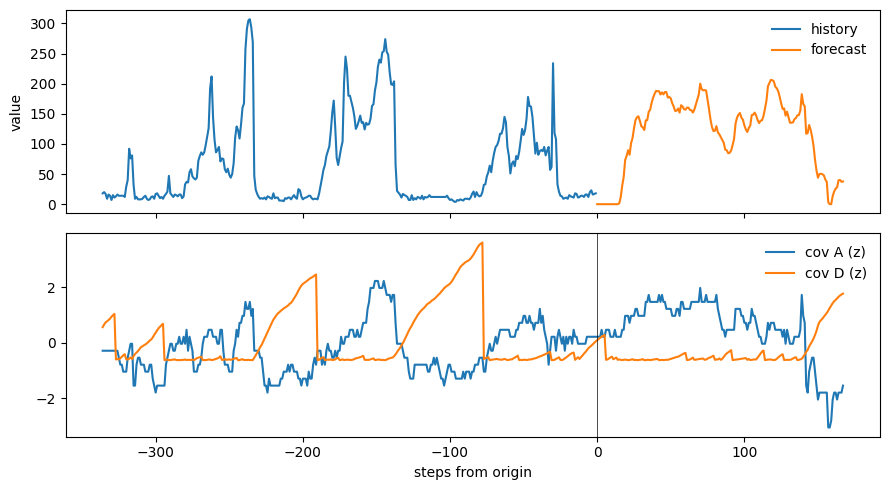

In [ ]:
# Task 2 v2: tiny Autoformer that learns a residual on top of a learnable mean-reversion baseline.
# Paste each block into its own Colab cell, in order. The "# %% CELL n" lines are only markers.
#
# Changes vs v1:
#   1. Delay band mask in Auto-Correlation (no lag 0 / mirrored lags; lags in [min_lag, L//2]).
#   2. evaluate() clips predictions at 0 (matches the leaderboard), so early stopping sees the real metric.
#   3. SETTINGS["device"] is respected.
#   4. Epoch count chosen on the selection blocks (CELL 6a) and then used for fixed-epoch runs and the refit.
#   5. Covariate screen on design data only (CELL 5b), so the covariate choice is documented and leak-free.
#   6. Report: block-bootstrap CI, per-fold RMSE table.
#   7. New baselines: seasonal-naive (24 and 168), "linhead" (baseline + linear covariate head, no
#      Autoformer) and "dlinear" (Zeng et al., 2023). New ablations: delay band, min_lag, L, kernel, log1p.
#   8. base_forecasts computed once per origin; OVERRIDES empty by default.


# %% CELL 1: settings. Edit MODE here, then re-run this cell and every cell below it.
import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
try:
    from IPython.display import display
except ImportError:
    display = print
MODE = os.environ.get("T2_MODE", "full")      # "debug" = CPU smoke test on a small slice; "full" = all data
DATA_DIR = os.environ.get("T2_DATA_DIR", "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data")
THREADS = 2
TARGET = "raw"          # "raw" or "log1p": transform applied to the target before normalising (loss is MSE in that space)
OVERRIDES = dict(seeds=[0, 1, 2])          # e.g. dict(folds=1, seeds=[0, 1, 2]) for a quick screening pass
FIXED_E = None          # set by CELL 6a; None = early stopping on the selection blocks

PRESETS = {
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=15, patience=4, bs=64, stride=2,
                 device="auto"),
}
SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cpu") if SETTINGS["device"] == "cpu" else torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} target={TARGET} folds={FOLDS} blocks/fold={NB} seeds={SEEDS} epochs<={EPOCHS}")


# %% CELL 2: data and leakage-safe preprocessing
CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
tr = tr.sort_values("time_idx").reset_index(drop=True)
ex = ex.sort_values("time_idx").reset_index(drop=True)
assert tr["time_idx"].iloc[0] == 1 and (tr["time_idx"].diff().dropna() == 1).all(), "student_train time_idx must run 1..T"
assert (ex["time_idx"].to_numpy() == np.arange(1, len(ex) + 1)).all(), "external file must run time_idx 1..N"
assert MODE != "full" or (len(tr) == 43656 and len(ex) == 43824), "unexpected file sizes"
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)


def geometry(k):
    """Rolling fold k (0 = latest): selection blocks, then report blocks, both NB x 168 steps."""
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0                     # (sel0, rep0); training uses targets before sel0


def tf(v):
    return np.log1p(v) if TARGET == "log1p" else v


def inv(z):
    """Normalised model space -> original units (differentiable not needed)."""
    z = z * SD + MU
    return torch.expm1(z.clamp(max=20.0)) if TARGET == "log1p" else z


def prep(fit_end):
    """Normalise with statistics from [0, fit_end) only, so nothing after it leaks."""
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    yt = tf(y)
    MU, SD = float(yt[:fit_end].mean()), float(yt[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (yt - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)


# %% CELL 3: configuration and models
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"    # autoformer | linhead (baseline + linear covariate head) | dlinear
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 8                  # model width
    heads: int = 2
    el: int = 1                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    delay_band: bool = True     # restrict delays to [min_lag, L//2] (False reproduces v1 behaviour)
    min_lag: int = 8            # smallest delay; choose from the ACF diagnostics (very short lags only measure smoothness)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept; confirm with CELL 5b
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 1            # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False
    use_ac: bool = True         # False = Auto-Correlation removed (ablation only; NOT a submittable model)
    use_decomp: bool = True     # False = series decomposition removed (ablation only)


def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


def logit(p):
    return math.log(p / (1 - p))


class Decomp(nn.Module):
    def __init__(s, k, on=True):
        super().__init__()
        s.k, s.on = k, on

    def forward(s, x):                                       # x [B,T,D] -> (remainder, trend)
        if not s.on:
            return x, torch.zeros_like(x)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c, s.band, s.lo, s.use = c.heads, c.c, c.delay_band, c.min_lag, c.use_ac
        if not s.use:                                        # ablation: sublayer outputs zeros, no parameters
            return
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))            # learnable softmax temperature

    def forward(s, q, k, v):
        if not s.use:
            return torch.zeros_like(q)
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)        # [B,h,dh,L]
        # score(tau) = sum_t q_t k_{t-tau}: same convention as the Task 1 delay scores
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        if s.band:                                           # only delays in [lo, L//2] may be selected
            lo, hi = s.lo, L // 2
            mask = torch.full((L,), float("-inf"), device=q.device)
            mask[lo:hi + 1] = 0.0
            score = score + mask
            kk = min(kk, hi - lo + 1)
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L                               # v[t - tau]
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)             # tied: same module, counted once in P
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


class Feats(nn.Module):
    """Side inputs: selected covariates, a learned category embedding, and Fourier harmonics."""
    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)                                # exact phase on the index
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


class Baseline(nn.Module):
    """level + phi^h * (now - level): a learnable mean-reversion forecast. 3 parameters (4 with `slow`).

    These numbers are registered as parameters on purpose, so they are counted in P.
    """
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))        # sigmoid -> memory per step
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))    # sigmoid -> smoothing rate of "now"
        s.level = nn.Parameter(torch.zeros(()))                  # long-run level (standardised units)
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))           # sigmoid -> weight on the slow level
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)                            # [B,1]
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)         # [B,H]


def cov_width(c):
    return (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = cov_width(c)
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k, c.use_decomp)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))                 # fixed, no parameters
        s.base = Baseline(c) if c.residual else None
        if c.residual:                                                           # start exactly at the baseline
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)                                                     # [B,L,1]
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)                  # trend starts at zero
        else:                                                                    # standard Autoformer trend init
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


class LinHead(nn.Module):
    """No Autoformer: learnable baseline + one linear map from the known-future features. Isolates what the
    Autoformer adds beyond baseline + covariates."""
    def __init__(s, c):
        super().__init__()
        s.c, s.feat, s.base = c, Feats(c), Baseline(c)
        din = (cov_width(c) if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.head = nn.Linear(din, 1) if din else None
        if s.head is not None:
            nn.init.zeros_(s.head.weight)
            nn.init.zeros_(s.head.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        out = s.base(yE, slow)
        fD = s.feat(cD, kD, tD, s.c.cov in ("dec", "both"))
        if s.head is not None and fD is not None:
            out = out + s.head(fD[:, -H:])[..., 0]
        return out


class DLinear(nn.Module):
    """DLinear with last-value anchoring (Zeng et al., 2023): linear maps on the trend and remainder."""
    def __init__(s, c):
        super().__init__()
        s.c, s.dc = c, Decomp(c.k, c.use_decomp)
        s.ls, s.lt = nn.Linear(c.L, H), nn.Linear(c.L, H)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        last = yE[:, -1:]
        seas, trend = s.dc((yE - last).unsqueeze(-1))
        return s.ls(seas[..., 0]) + s.lt(trend[..., 0]) + last


def build(c):
    return {"autoformer": Net, "linhead": LinHead, "dlinear": DLinear}[c.arch](c)


# %% CELL 4: batching, training, evaluation, arms, summary
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()                  # mean of the last W_slow steps before the window end
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


def blocks(a0, c):
    """Window starts for NB consecutive non-overlapping 168-step targets beginning at a0."""
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)


@torch.no_grad()
def evaluate(m, starts, c):
    """Predictions and targets in original units; predictions clipped at 0 (the target is non-negative)."""
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return inv(torch.cat(P)).clamp(min=0), inv(torch.cat(Tg))


def rmse_t(p, t):
    return (p - t).pow(2).mean().sqrt().item()


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def fit(c, seed, epochs, val=None):
    """Train with AdamW + cosine decay. With `val`, stop early (patience) and keep the best checkpoint;
    with val=None, train exactly `epochs` epochs."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = build(c).to(DEV)
    base_params = list(m.base.parameters()) if getattr(m, "base", None) is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:                                                # no weight decay on the baseline's few numbers
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1                                  # every target ends before FIT_END
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))                  # different window subset each epoch
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run


# Arms: each one is an RMSE-vs-P point.
BASE = Cfg()
ARMS = {
    # --- main ladder
    "plain":         replace(BASE, residual=False, cov="none", fourier=0),   # tiny plain Autoformer
    "base":          replace(BASE, cov="none", fourier=0),                   # + learnable baseline residual
    "dec":           replace(BASE, cov="dec", fourier=0),                    # + future-known covariates
    "both":          replace(BASE, cov="both", fourier=0),                   # + past covariates in the encoder
    "dec+f2":        replace(BASE, cov="dec", fourier=2),                    # + 2 Fourier harmonics (recommended)
    "dec+f2+slow":   replace(BASE, cov="dec", fourier=2, slow=True),         # + slow level (weak evidence)
    "dec+f2 d16":    replace(BASE, cov="dec", fourier=2, d=16),              # wider
    "dec+f2 untied": replace(BASE, cov="dec", fourier=2, tie_dec=False, share_qk=False, proj_out=True,
                             ff_mult=2, bias=True),                          # no parameter savings
    # --- optional-file ablation, clean pairs (requirement 4): base vs dec (no Fourier), base+f2 vs dec+f2
    "base+f2":       replace(BASE, cov="none", fourier=2),
    # --- do the two Autoformer mechanisms actually contribute? (requirement 1; ablations, not submittable)
    "dec+f2 noAC":     replace(BASE, cov="dec", fourier=2, use_ac=False),
    "dec+f2 noDecomp": replace(BASE, cov="dec", fourier=2, use_decomp=False),
    # --- is the Autoformer doing anything? (benchmarks)
    "linhead":       replace(BASE, arch="linhead", cov="dec", fourier=2),    # baseline + linear covariate head
    "dlinear":       replace(BASE, arch="dlinear", cov="none", fourier=0),   # Zeng et al. 2023
    # --- ablations around dec+f2
    "dec+f2 noband": replace(BASE, cov="dec", fourier=2, delay_band=False),  # v1 delay selection (lag 0 allowed)
    "dec+f2 lag2":   replace(BASE, cov="dec", fourier=2, min_lag=2),
    "dec+f2 lag16":  replace(BASE, cov="dec", fourier=2, min_lag=16),
    "dec+f2 L48":    replace(BASE, cov="dec", fourier=2, L=48),
    "dec+f2 L168":   replace(BASE, cov="dec", fourier=2, L=168),
    "dec+f2 k13":    replace(BASE, cov="dec", fourier=2, k=13),
    "dec+f2 k49":    replace(BASE, cov="dec", fourier=2, k=49),
}
# log1p target is a global switch (TARGET in CELL 1): re-run "dec+f2" with TARGET="log1p" and compare.


def base_forecasts(h):
    """Reference forecasts from history h only. Computed once per origin."""
    P = int(BASE.period)
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m),
            "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m),
            f"seasonal naive {P}": np.tile(h[-P:], math.ceil(H / P))[:H],
            "seasonal naive 168": h[-168:].copy()}


BASE_NAMES = list(base_forecasts(y[:500]))


def run_all(names, epochs=None):
    """epochs=None: early stopping on the selection blocks (up to EPOCHS). int or dict: fixed epoch count."""
    E = {a: {s: [] for s in SEEDS} for a in names}
    BE = {n: [] for n in BASE_NAMES}
    info = {a: dict(P=None, best=[], run=[], secs=0.0) for a in names}
    for k in range(FOLDS):
        sel0, rep0 = geometry(k)
        prep(sel0)
        origins = [rep0 + H * j for j in range(NB)]
        fc = [base_forecasts(y[:a]) for a in origins]
        for n in BASE_NAMES:
            BE[n].append(np.stack([f[n] - y[a:a + H] for f, a in zip(fc, origins)]))
        for a in names:
            c = ARMS[a]
            sel, rep = blocks(sel0, c), blocks(rep0, c)
            ep = epochs.get(a) if isinstance(epochs, dict) else epochs
            t0 = time.time()
            for sd in SEEDS:
                if ep is None:
                    m, best_ep, run = fit(c, sd, EPOCHS, val=sel)
                else:
                    m, best_ep, run = fit(c, sd, ep, val=None)
                p, t = evaluate(m, rep, c)
                E[a][sd].append((p - t).cpu().numpy())
                info[a]["P"] = count(m)
                info[a]["best"].append(best_ep)
                info[a]["run"].append(run)
            info[a]["secs"] += time.time() - t0
            print(f"fold {k} | {a:15s} | P={info[a]['P']:5d} | {time.time() - t0:6.1f}s for {len(SEEDS)} seeds",
                  flush=True)
    return E, BE, info


def choose_epochs(name, cands=(6, 10, 15)):
    """Pick the epoch count on the SELECTION blocks (never the report blocks): train each candidate to completion
    with its own cosine schedule, compare selection RMSE averaged over folds and seeds."""
    c = ARMS[name]
    res = {e: [] for e in cands}
    for k in range(FOLDS):
        sel0, _ = geometry(k)
        prep(sel0)
        sel = blocks(sel0, c)
        for sd in SEEDS:
            for e in cands:
                m, _, _ = fit(c, sd, e, val=None)
                res[e].append(rmse_t(*evaluate(m, sel, c)))
    tab = pd.DataFrame({"epochs": list(cands), "sel_RMSE": [np.mean(res[e]) for e in cands],
                        "sd": [np.std(res[e], ddof=1) if len(res[e]) > 1 else np.nan for e in cands]}).round(3)
    return int(tab.loc[tab.sel_RMSE.idxmin(), "epochs"]), tab


def boot_ci(d, blk=3, B=2000, seed=0):
    """Moving-block bootstrap CI for the mean of d (consecutive blocks are probably correlated)."""
    rng = np.random.default_rng(seed)
    n = len(d)
    blk = max(1, min(blk, n))
    nb = math.ceil(n / blk)
    starts = rng.integers(0, n - blk + 1, (B, nb))
    idx = (starts[:, :, None] + np.arange(blk)).reshape(B, -1)[:, :n]
    return np.percentile(d[idx].mean(1), [2.5, 97.5])


def gap(d):
    lo, hi = boot_ci(d)
    return float(d.mean()), float(d.std(ddof=1) / np.sqrt(len(d))), float(lo), float(hi)


def summarise(names, E, BE, info):
    """Returns (overall table, per-fold RMSE table). gap_vs_ACF < 0 = better than the ACF baseline."""
    base_err = {k: np.concatenate(v) for k, v in BE.items()}
    ref = (base_err["ACF shrink"] ** 2).mean(1)
    rows, frows = [], []

    def fold_rmse(e):
        return [float(np.sqrt((e[f * NB:(f + 1) * NB] ** 2).mean())) for f in range(FOLDS)]

    for k, e in base_err.items():
        g, se, lo, hi = gap((e ** 2).mean(1) - ref)
        rows.append(dict(arm=f"baseline: {k}", P=0, RMSE=np.sqrt((e ** 2).mean()), RMSE_sd=np.nan,
                         MSE=(e ** 2).mean(), MAE=np.abs(e).mean(), gap_vs_ACF=g, gap_SE=se,
                         gap_CI_lo=lo, gap_CI_hi=hi, epochs_run=np.nan, best_epoch=np.nan))
        frows.append(dict(arm=f"baseline: {k}", **{f"fold{f}": v for f, v in enumerate(fold_rmse(e))}))
    for a in names:
        per = [np.concatenate(E[a][s]) for s in SEEDS]
        rm = [np.sqrt((e ** 2).mean()) for e in per]
        d = np.mean([(e ** 2).mean(1) for e in per], 0) - ref                    # seed-averaged per-block MSE gap
        g, se, lo, hi = gap(d)
        rows.append(dict(arm=a, P=info[a]["P"], RMSE=np.mean(rm),
                         RMSE_sd=np.std(rm, ddof=1) if len(rm) > 1 else np.nan,
                         MSE=np.mean([(e ** 2).mean() for e in per]), MAE=np.mean([np.abs(e).mean() for e in per]),
                         gap_vs_ACF=g, gap_SE=se, gap_CI_lo=lo, gap_CI_hi=hi,
                         epochs_run=np.mean(info[a]["run"]), best_epoch=np.mean(info[a]["best"])))
        fr = np.mean([fold_rmse(e) for e in per], 0)
        frows.append(dict(arm=a, **{f"fold{f}": float(v) for f, v in enumerate(fr)}))
    return pd.DataFrame(rows).round(3), pd.DataFrame(frows).round(2)


def final_forecast(c, seeds, epochs):
    """Refit on all T points for a fixed number of epochs and forecast time_idx T+1 .. T+168."""
    assert c.arch == "autoformer" and c.use_ac and c.use_decomp, \
        "submitted model must be an Autoformer with Series Decomposition AND Auto-Correlation (req. 2.4.1)"
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs, val=None)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)                      # the target is non-negative
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f}, "
          f"zeros={(out == 0).sum()})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}.")
    print("E to declare = the epochs used to choose the epoch count (CELL 6a, if you count them) + these refit "
          "epochs. Confirm with the TAs whether ablation runs must also be counted.")
    print("\nPaste this into the leaderboard:\n" + txt)
    return out


def plot_forecast(out, cov=("A", "D"), back=336):
    """Sanity check: forecast vs recent history, and the known-future covariates it can react to."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(range(-back, 0), y[-back:], label="history")
    ax[0].plot(range(0, H), out, label="forecast")
    ax[0].set_ylabel("value"); ax[0].legend(frameon=False)
    for cname in cov:
        j = CONT.index(cname)
        v = C[T - back:T + H, j]
        ax[1].plot(range(-back, H), (v - v.mean()) / (v.std() + 1e-9), label=f"cov {cname} (z)")
    ax[1].axvline(0, color="k", lw=0.5); ax[1].legend(frameon=False); ax[1].set_xlabel("steps from origin")
    fig.tight_layout(); fig.savefig("forecast_plot.png", dpi=130)
    plt.show()


# %% CELL 5: parameter counts and shape smoke test (fast; run this before the experiments)
prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = build(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:15s} {count(m):6d}")


# %% CELL 5b: covariate screen on DESIGN data only (earliest selection start across folds).
# Which known-future covariates carry signal about what the ACF baseline misses? Use this to justify Cfg.cont.
def screen_covariates(nsamp=300, seed=0):
    end = geometry(FOLDS - 1)[0]
    rng = np.random.default_rng(seed)
    origins = rng.integers(max(336, 1), end - H, nsamp)
    res, cv, ct = [], [], []
    for a in origins:
        f = base_forecasts(y[:a])["ACF shrink"]
        res.append(y[a:a + H] - f)
        cv.append(C[a:a + H])
        ct.append(cat_id[a:a + H])
    r, cv, ct = np.concatenate(res), np.concatenate(cv), np.concatenate(ct)
    df_ = pd.DataFrame(cv, columns=list(CONT))
    out = pd.DataFrame({"pearson": df_.corrwith(pd.Series(r)),
                        "spearman": df_.corrwith(pd.Series(r), method="spearman")}).round(3)
    gm = r.mean()
    eta2 = sum(((ct == g).sum() * (r[ct == g].mean() - gm) ** 2) for g in np.unique(ct)) / ((r - gm) ** 2).sum()
    print(f"design region = first {end} steps; {nsamp} random origins x {H} future steps")
    display(out)
    print(f"category (G-J) eta^2 vs baseline residual: {eta2:.3f}")
    print("top-2 by |spearman|:", list(out.spearman.abs().sort_values(ascending=False).index[:2]),
          "| current Cfg.cont:", BASE.cont)
    return out


_ = screen_covariates()


# %% CELL 6a: choose the epoch count on the selection blocks (optional but recommended; then FIXED_E is used)
_F, _S = FOLDS, SEEDS
FOLDS, SEEDS = 1, [0, 1, 2]
best_e, tab = choose_epochs("dec+f2", (6, 10))
FOLDS, SEEDS = _F, _S
display(tab)
FIXED_E = best_e
print("FIXED_E =", FIXED_E, "(applied to every arm below; set FIXED_E = None to use early stopping instead)")


# %% CELL 6b: run the experiments (the slow cell)
ARMS_TO_RUN = ["base+f2", "dec+f2", "dec+f2 noAC", "linhead"]
names = list(ARMS) if ARMS_TO_RUN is None else ARMS_TO_RUN
E, BE, info = run_all(names, epochs=FIXED_E)
df, fold_df = summarise(names, E, BE, info)
print("\nReport blocks, pooled over folds; gap_vs_ACF < 0 means better than the ACF baseline "
      "(CI = moving-block bootstrap over blocks)")
display(df.sort_values("P"))
print("\nPer-fold RMSE (seed-averaged)")
display(fold_df)
df.to_csv("task2_results.csv", index=False)
fold_df.to_csv("task2_results_by_fold.csv", index=False)


# %% CELL 7: final 168-step forecast (run only after you have chosen an arm and an epoch count)
FINAL_ARM = "dec+f2"
FINAL_EPOCHS = FIXED_E if FIXED_E else 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)
plot_forecast(forecast, cov=ARMS[FINAL_ARM].cont)

#final run


mode=full device=cuda target=raw folds=3 blocks/fold=20 seeds=[0, 1, 2] epochs<=15
T = 43656 | N = 43824
parameter counts (the script's own count is the one to declare):
  dec+f2             703
design region = first 30216 steps; 300 random origins x 168 future steps


,pearson,spearman
A,0.217,0.320
B,-0.046,0.037
C,-0.108,-0.174
D,-0.260,-0.368
E,0.054,0.062
F,-0.049,0.005


category (G-J) eta^2 vs baseline residual: 0.074
top-2 by |spearman|: ['D', 'A'] | current Cfg.cont: ('A', 'D')


,epochs,sel_RMSE,sd
0,6,54.876,0.720
1,20,53.922,1.149


saved forecast_168.txt (168 values, first=0.00, last=49.87, zeros=18)
declare P = 703 (sum over 1 model(s)); refit epochs = 20.

 output:0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.7382,9.2439,26.0401,36.9680,63.4656,66.9247,76.2096,69.0208,87.9057,94.5392,110.8569,125.6828,127.4419,128.8579,123.1206,114.4761,110.3761,107.5958,124.5572,125.6053,135.4422,135.5251,143.2518,148.2214,153.7387,161.4908,162.9464,163.9024,156.2949,161.2801,158.6768,162.0945,161.2444,152.1173,151.3823,148.4171,138.2463,133.2429,129.3215,130.4311,132.9927,125.3843,135.4954,136.0187,136.5471,136.8870,138.0260,136.8001,131.0097,131.1570,132.4755,140.0156,145.8161,152.8929,158.4750,175.8073,165.8505,161.9271,161.2793,164.1134,150.4342,136.8732,123.5920,115.2064,109.5483,109.4436,113.9496,103.3204,99.0071,96.0897,89.5225,84.8839,72.5361,72.1612,69.5337,73.6433,78.8483,85.9228,95.6317,121.4019,128.8091,132.6179,133.7313,126.1211,126.6410,119.4872,116.600

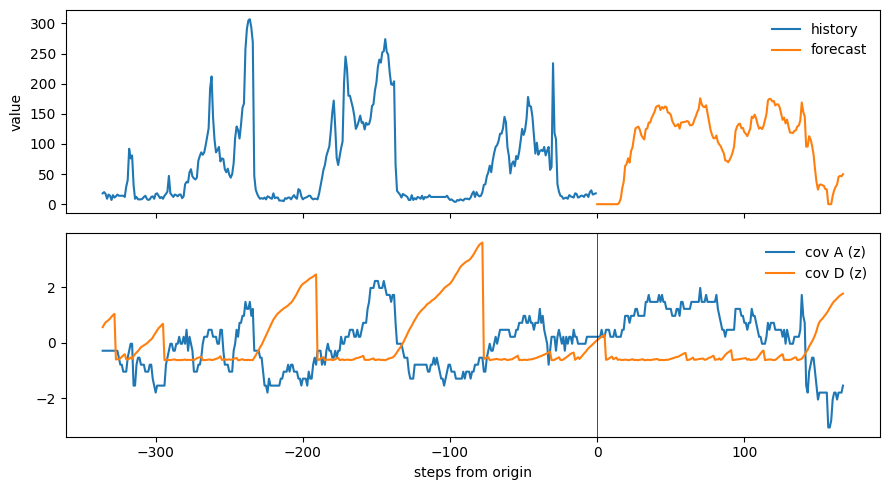

In [ ]:


# %% CELL 1: settings. Edit MODE here, then re-run this cell and every cell below it.
import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
try:
    from IPython.display import display
except ImportError:
    display = print
MODE = os.environ.get("T2_MODE", "full")      # "debug" = CPU smoke test on a small slice; "full" = all data
DATA_DIR = os.environ.get("T2_DATA_DIR", "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data")
THREADS = 2
TARGET = "raw"          # "raw" or "log1p": transform applied to the target before normalising (loss is MSE in that space)
OVERRIDES = dict(seeds=[0, 1, 2])          # e.g. dict(folds=1, seeds=[0, 1, 2]) for a quick screening pass
FIXED_E = None          # set by CELL 6a; None = early stopping on the selection blocks

PRESETS = {
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=15, patience=4, bs=64, stride=2,
                 device="auto"),
}
SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cpu") if SETTINGS["device"] == "cpu" else torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} target={TARGET} folds={FOLDS} blocks/fold={NB} seeds={SEEDS} epochs<={EPOCHS}")


# %% CELL 2: data and leakage-safe preprocessing
CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
tr = tr.sort_values("time_idx").reset_index(drop=True)
ex = ex.sort_values("time_idx").reset_index(drop=True)
assert tr["time_idx"].iloc[0] == 1 and (tr["time_idx"].diff().dropna() == 1).all(), "student_train time_idx must run 1..T"
assert (ex["time_idx"].to_numpy() == np.arange(1, len(ex) + 1)).all(), "external file must run time_idx 1..N"
assert MODE != "full" or (len(tr) == 43656 and len(ex) == 43824), "unexpected file sizes"
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)


def geometry(k):
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0                     # (sel0, rep0); training uses targets before sel0


def tf(v):
    return np.log1p(v) if TARGET == "log1p" else v


def inv(z):
    """Normalised model space -> original units (differentiable not needed)."""
    z = z * SD + MU
    return torch.expm1(z.clamp(max=20.0)) if TARGET == "log1p" else z


def prep(fit_end):
    """Normalise with statistics from [0, fit_end) only, so nothing after it leaks."""
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    yt = tf(y)
    MU, SD = float(yt[:fit_end].mean()), float(yt[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (yt - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)


# %% CELL 3: configuration and models
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"    # autoformer | linhead (baseline + linear covariate head) | dlinear
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 8                  # model width
    heads: int = 2
    el: int = 1                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    delay_band: bool = True     # restrict delays to [min_lag, L//2] (False reproduces v1 behaviour)
    min_lag: int = 8            # smallest delay; choose from the ACF diagnostics (very short lags only measure smoothness)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept; confirm with CELL 5b
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 1            # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False
    use_ac: bool = True         # False = Auto-Correlation removed (ablation only; NOT a submittable model)
    use_decomp: bool = True     # False = series decomposition removed (ablation only)


def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


def logit(p):
    return math.log(p / (1 - p))


class Decomp(nn.Module):
    def __init__(s, k, on=True):
        super().__init__()
        s.k, s.on = k, on

    def forward(s, x):                                       # x [B,T,D] -> (remainder, trend)
        if not s.on:
            return x, torch.zeros_like(x)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c, s.band, s.lo, s.use = c.heads, c.c, c.delay_band, c.min_lag, c.use_ac
        if not s.use:                                        # ablation: sublayer outputs zeros, no parameters
            return
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))            # learnable softmax temperature

    def forward(s, q, k, v):
        if not s.use:
            return torch.zeros_like(q)
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)        # [B,h,dh,L]
        # score(tau) = sum_t q_t k_{t-tau}: same convention as the Task 1 delay scores
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        if s.band:                                           # only delays in [lo, L//2] may be selected
            lo, hi = s.lo, L // 2
            mask = torch.full((L,), float("-inf"), device=q.device)
            mask[lo:hi + 1] = 0.0
            score = score + mask
            kk = min(kk, hi - lo + 1)
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L                               # v[t - tau]
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)             # tied: same module, counted once in P
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


class Feats(nn.Module):
    """Side inputs: selected covariates, a learned category embedding, and Fourier harmonics."""
    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)                                # exact phase on the index
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


class Baseline(nn.Module):
    """level + phi^h * (now - level): a learnable mean-reversion forecast. 3 parameters (4 with `slow`).

    These numbers are registered as parameters on purpose, so they are counted in P.
    """
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))        # sigmoid -> memory per step
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))    # sigmoid -> smoothing rate of "now"
        s.level = nn.Parameter(torch.zeros(()))                  # long-run level (standardised units)
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))           # sigmoid -> weight on the slow level
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)                            # [B,1]
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)         # [B,H]


def cov_width(c):
    return (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = cov_width(c)
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k, c.use_decomp)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))                 # fixed, no parameters
        s.base = Baseline(c) if c.residual else None
        if c.residual:                                                           # start exactly at the baseline
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)                                                     # [B,L,1]
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)                  # trend starts at zero
        else:                                                                    # standard Autoformer trend init
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


def build(c):
    return Net(c)


# %% CELL 4: batching, training, evaluation, arms, summary
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()                  # mean of the last W_slow steps before the window end
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


def blocks(a0, c):
    """Window starts for NB consecutive non-overlapping 168-step targets beginning at a0."""
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)


@torch.no_grad()
def evaluate(m, starts, c):
    """Predictions and targets in original units; predictions clipped at 0 (the target is non-negative)."""
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return inv(torch.cat(P)).clamp(min=0), inv(torch.cat(Tg))


def rmse_t(p, t):
    return (p - t).pow(2).mean().sqrt().item()


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def fit(c, seed, epochs, val=None):
    """Train with AdamW + cosine decay. With `val`, stop early (patience) and keep the best checkpoint;
    with val=None, train exactly `epochs` epochs."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = build(c).to(DEV)
    base_params = list(m.base.parameters()) if getattr(m, "base", None) is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:                                                # no weight decay on the baseline's few numbers
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1                                  # every target ends before FIT_END
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))                  # different window subset each epoch
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run


# Arms: each one is an RMSE-vs-P point.
BASE = Cfg()
ARMS = {"dec+f2":        replace(BASE, cov="dec", fourier=2)
}
# log1p target is a global switch (TARGET in CELL 1): re-run "dec+f2" with TARGET="log1p" and compare.


def base_forecasts(h):
    """Reference forecasts from history h only. Computed once per origin."""
    P = int(BASE.period)
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m),
            "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m),
            f"seasonal naive {P}": np.tile(h[-P:], math.ceil(H / P))[:H],
            "seasonal naive 168": h[-168:].copy()}


BASE_NAMES = list(base_forecasts(y[:500]))


def choose_epochs(name, cands=(6, 10, 15)):
    """Pick the epoch count on the SELECTION blocks (never the report blocks): train each candidate to completion
    with its own cosine schedule, compare selection RMSE averaged over folds and seeds."""
    c = ARMS[name]
    res = {e: [] for e in cands}
    for k in range(FOLDS):
        sel0, _ = geometry(k)
        prep(sel0)
        sel = blocks(sel0, c)
        for sd in SEEDS:
            for e in cands:
                m, _, _ = fit(c, sd, e, val=None)
                res[e].append(rmse_t(*evaluate(m, sel, c)))
    tab = pd.DataFrame({"epochs": list(cands), "sel_RMSE": [np.mean(res[e]) for e in cands],
                        "sd": [np.std(res[e], ddof=1) if len(res[e]) > 1 else np.nan for e in cands]}).round(3)
    return int(tab.loc[tab.sel_RMSE.idxmin(), "epochs"]), tab



def final_forecast(c, seeds, epochs):
    """Refit on all T points for a fixed number of epochs and forecast time_idx T+1 .. T+168."""
    assert c.arch == "autoformer" and c.use_ac and c.use_decomp, \
        "submitted model must be an Autoformer with Series Decomposition AND Auto-Correlation (req. 2.4.1)"
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs, val=None)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)                      # the target is non-negative
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f}, "
          f"zeros={(out == 0).sum()})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}.")

    print("\n output:"+ txt)

    return out


def plot_forecast(out, cov=("A", "D"), back=336):
    """Sanity check: forecast vs recent history, and the known-future covariates it can react to."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(range(-back, 0), y[-back:], label="history")
    ax[0].plot(range(0, H), out, label="forecast")
    ax[0].set_ylabel("value"); ax[0].legend(frameon=False)
    for cname in cov:
        j = CONT.index(cname)
        v = C[T - back:T + H, j]
        ax[1].plot(range(-back, H), (v - v.mean()) / (v.std() + 1e-9), label=f"cov {cname} (z)")
    ax[1].axvline(0, color="k", lw=0.5); ax[1].legend(frameon=False); ax[1].set_xlabel("steps from origin")
    fig.tight_layout(); fig.savefig("forecast_plot.png", dpi=130)
    plt.show()


# %% CELL 5: parameter counts and shape smoke test (fast; run this before the experiments)
prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = build(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:15s} {count(m):6d}")


# %% CELL 5b: covariate screen on DESIGN data only (earliest selection start across folds).
# Which known-future covariates carry signal about what the ACF baseline misses? Use this to justify Cfg.cont.
def screen_covariates(nsamp=300, seed=0):
    end = geometry(FOLDS - 1)[0]
    rng = np.random.default_rng(seed)
    origins = rng.integers(max(336, 1), end - H, nsamp)
    res, cv, ct = [], [], []
    for a in origins:
        f = base_forecasts(y[:a])["ACF shrink"]
        res.append(y[a:a + H] - f)
        cv.append(C[a:a + H])
        ct.append(cat_id[a:a + H])
    r, cv, ct = np.concatenate(res), np.concatenate(cv), np.concatenate(ct)
    df_ = pd.DataFrame(cv, columns=list(CONT))
    out = pd.DataFrame({"pearson": df_.corrwith(pd.Series(r)),
                        "spearman": df_.corrwith(pd.Series(r), method="spearman")}).round(3)
    gm = r.mean()
    eta2 = sum(((ct == g).sum() * (r[ct == g].mean() - gm) ** 2) for g in np.unique(ct)) / ((r - gm) ** 2).sum()
    print(f"design region = first {end} steps; {nsamp} random origins x {H} future steps")
    display(out)
    print(f"category (G-J) eta^2 vs baseline residual: {eta2:.3f}")
    print("top-2 by |spearman|:", list(out.spearman.abs().sort_values(ascending=False).index[:2]),
          "| current Cfg.cont:", BASE.cont)
    return out


_ = screen_covariates()


# %% CELL 6a: choose the epoch count on the selection blocks (optional but recommended; then FIXED_E is used)
_F, _S = FOLDS, SEEDS
FOLDS, SEEDS = 1, [0, 1, 2]
best_e, tab = choose_epochs("dec+f2", (6, 20))
FOLDS, SEEDS = _F, _S
display(tab)
FIXED_E = best_e


FINAL_ARM = "dec+f2"
FINAL_EPOCHS = FIXED_E if FIXED_E else 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)
plot_forecast(forecast, cov=ARMS[FINAL_ARM].cont)

# go back to untied


In [ ]:


# %% CELL 1: settings. Edit MODE here, then re-run this cell and every cell below it.
import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
try:
    from IPython.display import display
except ImportError:
    display = print
MODE = os.environ.get("T2_MODE", "full")      # "debug" = CPU smoke test on a small slice; "full" = all data
DATA_DIR = os.environ.get("T2_DATA_DIR", "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data")
THREADS = 2
TARGET = "raw"          # "raw" or "log1p": transform applied to the target before normalising (loss is MSE in that space)
OVERRIDES = dict(seeds=[0, 1, 2])          # e.g. dict(folds=1, seeds=[0, 1, 2]) for a quick screening pass
FIXED_E = None          # set by CELL 6a; None = early stopping on the selection blocks

PRESETS = {
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=15, patience=4, bs=64, stride=2,
                 device="auto"),
}
SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cpu") if SETTINGS["device"] == "cpu" else torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} target={TARGET} folds={FOLDS} blocks/fold={NB} seeds={SEEDS} epochs<={EPOCHS}")


# %% CELL 2: data and leakage-safe preprocessing
CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
tr = tr.sort_values("time_idx").reset_index(drop=True)
ex = ex.sort_values("time_idx").reset_index(drop=True)
assert tr["time_idx"].iloc[0] == 1 and (tr["time_idx"].diff().dropna() == 1).all(), "student_train time_idx must run 1..T"
assert (ex["time_idx"].to_numpy() == np.arange(1, len(ex) + 1)).all(), "external file must run time_idx 1..N"
assert MODE != "full" or (len(tr) == 43656 and len(ex) == 43824), "unexpected file sizes"
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)


def geometry(k):
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0                     # (sel0, rep0); training uses targets before sel0


def tf(v):
    return np.log1p(v) if TARGET == "log1p" else v


def inv(z):
    """Normalised model space -> original units (differentiable not needed)."""
    z = z * SD + MU
    return torch.expm1(z.clamp(max=20.0)) if TARGET == "log1p" else z


def prep(fit_end):
    """Normalise with statistics from [0, fit_end) only, so nothing after it leaks."""
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    yt = tf(y)
    MU, SD = float(yt[:fit_end].mean()), float(yt[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (yt - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)


# %% CELL 3: configuration and models
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"    # autoformer | linhead (baseline + linear covariate head) | dlinear
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 8                  # model width
    heads: int = 2
    el: int = 1                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    delay_band: bool = True     # restrict delays to [min_lag, L//2] (False reproduces v1 behaviour)
    min_lag: int = 8            # smallest delay; choose from the ACF diagnostics (very short lags only measure smoothness)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept; confirm with CELL 5b
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 1            # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False
    use_ac: bool = True         # False = Auto-Correlation removed (ablation only; NOT a submittable model)
    use_decomp: bool = True     # False = series decomposition removed (ablation only)


def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


def logit(p):
    return math.log(p / (1 - p))


class Decomp(nn.Module):
    def __init__(s, k, on=True):
        super().__init__()
        s.k, s.on = k, on

    def forward(s, x):                                       # x [B,T,D] -> (remainder, trend)
        if not s.on:
            return x, torch.zeros_like(x)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c, s.band, s.lo, s.use = c.heads, c.c, c.delay_band, c.min_lag, c.use_ac
        if not s.use:                                        # ablation: sublayer outputs zeros, no parameters
            return
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))            # learnable softmax temperature

    def forward(s, q, k, v):
        if not s.use:
            return torch.zeros_like(q)
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)        # [B,h,dh,L]
        # score(tau) = sum_t q_t k_{t-tau}: same convention as the Task 1 delay scores
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        if s.band:                                           # only delays in [lo, L//2] may be selected
            lo, hi = s.lo, L // 2
            mask = torch.full((L,), float("-inf"), device=q.device)
            mask[lo:hi + 1] = 0.0
            score = score + mask
            kk = min(kk, hi - lo + 1)
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L                               # v[t - tau]
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)             # tied: same module, counted once in P
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


class Feats(nn.Module):
    """Side inputs: selected covariates, a learned category embedding, and Fourier harmonics."""
    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)                                # exact phase on the index
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


class Baseline(nn.Module):
    """level + phi^h * (now - level): a learnable mean-reversion forecast. 3 parameters (4 with `slow`).

    These numbers are registered as parameters on purpose, so they are counted in P.
    """
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))        # sigmoid -> memory per step
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))    # sigmoid -> smoothing rate of "now"
        s.level = nn.Parameter(torch.zeros(()))                  # long-run level (standardised units)
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))           # sigmoid -> weight on the slow level
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)                            # [B,1]
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)         # [B,H]


def cov_width(c):
    return (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = cov_width(c)
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k, c.use_decomp)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))                 # fixed, no parameters
        s.base = Baseline(c) if c.residual else None
        if c.residual:                                                           # start exactly at the baseline
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)                                                     # [B,L,1]
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)                  # trend starts at zero
        else:                                                                    # standard Autoformer trend init
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


def build(c):
    return Net(c)


In [ ]:


# %% CELL 4: batching, training, evaluation, arms, summary
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()                  # mean of the last W_slow steps before the window end
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


def blocks(a0, c):
    """Window starts for NB consecutive non-overlapping 168-step targets beginning at a0."""
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)


@torch.no_grad()
def evaluate(m, starts, c):
    """Predictions and targets in original units; predictions clipped at 0 (the target is non-negative)."""
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return inv(torch.cat(P)).clamp(min=0), inv(torch.cat(Tg))


def rmse_t(p, t):
    return (p - t).pow(2).mean().sqrt().item()


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def fit(c, seed, epochs, val=None):
    """Train with AdamW + cosine decay. With `val`, stop early (patience) and keep the best checkpoint;
    with val=None, train exactly `epochs` epochs."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = build(c).to(DEV)
    base_params = list(m.base.parameters()) if getattr(m, "base", None) is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:                                                # no weight decay on the baseline's few numbers
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1                                  # every target ends before FIT_END
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))                  # different window subset each epoch
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run


# Arms: each one is an RMSE-vs-P point.
BASE = replace(Cfg(), tie_dec=False, share_qk=False, proj_out=True, ff_mult=2, bias=True)   # "untied"

ARMS = {"dec+f2 untied":        replace(BASE, cov="dec", fourier=2)
}
# log1p target is a global switch (TARGET in CELL 1): re-run "dec+f2" with TARGET="log1p" and compare.


def base_forecasts(h):
    """Reference forecasts from history h only. Computed once per origin."""
    P = int(BASE.period)
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m),
            "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m),
            f"seasonal naive {P}": np.tile(h[-P:], math.ceil(H / P))[:H],
            "seasonal naive 168": h[-168:].copy()}


BASE_NAMES = list(base_forecasts(y[:500]))


def choose_epochs(name, cands=(6, 10, 15)):
    """Pick the epoch count on the SELECTION blocks (never the report blocks): train each candidate to completion
    with its own cosine schedule, compare selection RMSE averaged over folds and seeds."""
    c = ARMS[name]
    res = {e: [] for e in cands}
    for k in range(FOLDS):
        sel0, _ = geometry(k)
        prep(sel0)
        sel = blocks(sel0, c)
        for sd in SEEDS:
            for e in cands:
                m, _, _ = fit(c, sd, e, val=None)
                res[e].append(rmse_t(*evaluate(m, sel, c)))
    tab = pd.DataFrame({"epochs": list(cands), "sel_RMSE": [np.mean(res[e]) for e in cands],
                        "sd": [np.std(res[e], ddof=1) if len(res[e]) > 1 else np.nan for e in cands]}).round(3)
    return int(tab.loc[tab.sel_RMSE.idxmin(), "epochs"]), tab



def final_forecast(c, seeds, epochs):
    """Refit on all T points for a fixed number of epochs and forecast time_idx T+1 .. T+168."""
    assert c.arch == "autoformer" and c.use_ac and c.use_decomp, \
        "submitted model must be an Autoformer with Series Decomposition AND Auto-Correlation (req. 2.4.1)"
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs, val=None)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)                      # the target is non-negative
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f}, "
          f"zeros={(out == 0).sum()})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}.")

    print("\n output:"+ txt)

    return out


def plot_forecast(out, cov=("A", "D"), back=336):
    """Sanity check: forecast vs recent history, and the known-future covariates it can react to."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(range(-back, 0), y[-back:], label="history")
    ax[0].plot(range(0, H), out, label="forecast")
    ax[0].set_ylabel("value"); ax[0].legend(frameon=False)
    for cname in cov:
        j = CONT.index(cname)
        v = C[T - back:T + H, j]
        ax[1].plot(range(-back, H), (v - v.mean()) / (v.std() + 1e-9), label=f"cov {cname} (z)")
    ax[1].axvline(0, color="k", lw=0.5); ax[1].legend(frameon=False); ax[1].set_xlabel("steps from origin")
    fig.tight_layout(); fig.savefig("forecast_plot.png", dpi=130)
    plt.show()


# %% CELL 5: parameter counts and shape smoke test (fast; run this before the experiments)
prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = build(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:15s} {count(m):6d}")


# %% CELL 5b: covariate screen on DESIGN data only (earliest selection start across folds).
# Which known-future covariates carry signal about what the ACF baseline misses? Use this to justify Cfg.cont.
def screen_covariates(nsamp=300, seed=0):
    end = geometry(FOLDS - 1)[0]
    rng = np.random.default_rng(seed)
    origins = rng.integers(max(336, 1), end - H, nsamp)
    res, cv, ct = [], [], []
    for a in origins:
        f = base_forecasts(y[:a])["ACF shrink"]
        res.append(y[a:a + H] - f)
        cv.append(C[a:a + H])
        ct.append(cat_id[a:a + H])
    r, cv, ct = np.concatenate(res), np.concatenate(cv), np.concatenate(ct)
    df_ = pd.DataFrame(cv, columns=list(CONT))
    out = pd.DataFrame({"pearson": df_.corrwith(pd.Series(r)),
                        "spearman": df_.corrwith(pd.Series(r), method="spearman")}).round(3)
    gm = r.mean()
    eta2 = sum(((ct == g).sum() * (r[ct == g].mean() - gm) ** 2) for g in np.unique(ct)) / ((r - gm) ** 2).sum()
    print(f"design region = first {end} steps; {nsamp} random origins x {H} future steps")
    display(out)
    print(f"category (G-J) eta^2 vs baseline residual: {eta2:.3f}")
    print("top-2 by |spearman|:", list(out.spearman.abs().sort_values(ascending=False).index[:2]),
          "| current Cfg.cont:", BASE.cont)
    return out


_ = screen_covariates()


parameter counts (the script's own count is the one to declare):
  dec+f2 untied     1584
design region = first 30216 steps; 300 random origins x 168 future steps


,pearson,spearman
A,0.217,0.320
B,-0.046,0.037
C,-0.108,-0.174
D,-0.260,-0.368
E,0.054,0.062
F,-0.049,0.005


category (G-J) eta^2 vs baseline residual: 0.074
top-2 by |spearman|: ['D', 'A'] | current Cfg.cont: ('A', 'D')


fold 0 seed 0: best epoch 4, epochs run 8, 50s
fold 0 seed 1: best epoch 9, epochs run 13, 64s
fold 0 seed 2: best epoch 3, epochs run 7, 34s
fold 1 seed 0: best epoch 11, epochs run 15, 65s
fold 1 seed 1: best epoch 5, epochs run 9, 39s
fold 1 seed 2: best epoch 3, epochs run 7, 31s
fold 2 seed 0: best epoch 5, epochs run 9, 34s
fold 2 seed 1: best epoch 4, epochs run 8, 31s
fold 2 seed 2: best epoch 6, epochs run 10, 38s


,model,P,RMSE,MAE,sMAPE,RMSE_sd,gap_vs_ACF,gap_SE
0,baseline: global mean,0,94.363,70.677,77.721,NaN,NaN,NaN
1,baseline: ACF shrink,0,88.905,66.283,73.945,NaN,NaN,NaN
2,baseline: seasonal naive 24,0,132.591,92.417,92.982,NaN,NaN,NaN
3,baseline: seasonal naive 168,0,130.830,92.818,92.906,NaN,NaN,NaN
4,dec+f2 untied (mean of 3 seeds),1584,66.817,47.724,65.703,0.894,-3439.098,591.46


best epochs: [4, 9, 3, 11, 5, 3, 5, 4, 6] | epochs run: [8, 13, 7, 15, 9, 7, 9, 8, 10] | FIXED_E = 5


,parameter,shape,count
0,feat.emb.weight,"(4, 2)",8
1,ei.weight,"(8, 5)",40
2,ei.bias,"(8,)",8
3,di.weight,"(8, 9)",72
4,di.bias,"(8,)",8
5,enc.0.a.log_tau,(),1
6,enc.0.a.wq.weight,"(8, 8)",64
7,enc.0.a.wq.bias,"(8,)",8
8,enc.0.a.wk.weight,"(8, 8)",64
9,enc.0.a.wk.bias,"(8,)",8


P = 1584 (counting shared modules at every use: 1584)
['time_idx', 'value'] (168, 2)
student_test.csv alignment OK
saved forecast_168.txt (168 values, first=13.04, last=0.00, zeros=15)
declare P = 1584 (sum over 1 model(s)); refit epochs = 5.

 output:13.0377,16.7032,17.7780,16.0681,11.7182,4.4253,18.7961,26.1196,29.8184,36.1049,34.7940,32.4240,32.0615,36.6526,45.2471,53.9180,56.9465,62.7592,64.7389,78.4916,82.4298,97.1574,92.7678,103.3902,106.0298,116.8168,121.9269,114.7500,117.1234,109.9989,103.7963,97.8056,96.0705,113.2291,116.0191,119.9245,119.4745,119.4929,113.7162,110.9532,111.3780,114.1180,120.9834,119.9795,124.2220,125.7455,126.6978,122.6088,116.2582,112.1130,107.9170,106.0229,108.8644,108.8507,110.4207,106.7467,100.4114,108.9158,109.4938,105.1513,102.2982,105.4202,105.8918,105.0436,105.5373,102.8669,104.1859,106.1462,106.7431,108.6891,116.7954,112.8919,115.6379,117.3725,117.4891,111.8990,106.7952,101.1559,94.9450,88.1797,87.2146,88.0324,80.6043,75.0857,67.1443,62.9665,58.9849,

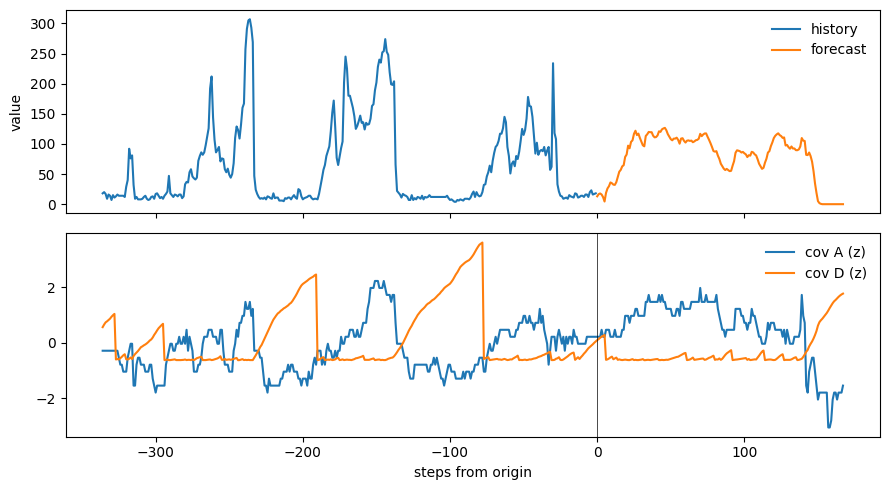

In [ ]:
# UNTESTED. Run these two cells after Cells 1-5b, with BASE already set to the untied configuration.
# Do NOT run the old 6a or 6c.


# %% CELL V: validate ONLY dec+f2 (untied) on the report blocks, and get the epoch count from early stopping
ARM = "dec+f2 untied"


def metr(p, t):
    e = p - t
    return dict(RMSE=float(np.sqrt((e ** 2).mean())), MAE=float(np.abs(e).mean()),
                sMAPE=float((200 * np.abs(e) / (np.abs(p) + np.abs(t) + 1e-8)).mean()))


def validate_one(name):
    c = ARMS[name]
    preds, TG, BE = {s: [] for s in SEEDS}, [], {n: [] for n in BASE_NAMES}
    best, run, P = [], [], None
    for k in range(FOLDS):
        sel0, rep0 = geometry(k)
        prep(sel0)
        origins = [rep0 + H * j for j in range(NB)]
        TG.append(np.stack([y[a:a + H] for a in origins]))
        for n in BE:
            BE[n].append(np.stack([base_forecasts(y[:a])[n] for a in origins]))
        sel, rep = blocks(sel0, c), blocks(rep0, c)
        for sd in SEEDS:
            t0 = time.time()
            m, b, r = fit(c, sd, EPOCHS, val=sel)              # early stopping on the SELECTION blocks only
            p, _ = evaluate(m, rep, c)                         # scored on the separate REPORT blocks
            preds[sd].append(p.cpu().numpy())
            best.append(b)
            run.append(r)
            P = count(m)
            print(f"fold {k} seed {sd}: best epoch {b}, epochs run {r}, {time.time() - t0:.0f}s", flush=True)
    T_ = np.concatenate(TG)
    per = [np.concatenate(preds[s]) for s in SEEDS]
    ms = [metr(p, T_) for p in per]
    acf_mse = ((np.concatenate(BE["ACF shrink"]) - T_) ** 2).mean(1)
    d = np.mean([((p - T_) ** 2).mean(1) for p in per], 0) - acf_mse          # paired per-block MSE gap
    rows = [dict(model=f"baseline: {n}", P=0, **metr(np.concatenate(v), T_)) for n, v in BE.items()]
    rows.append(dict(model=f"{name} (mean of {len(SEEDS)} seeds)", P=P,
                     RMSE=np.mean([m["RMSE"] for m in ms]), RMSE_sd=np.std([m["RMSE"] for m in ms], ddof=1),
                     MAE=np.mean([m["MAE"] for m in ms]), sMAPE=np.mean([m["sMAPE"] for m in ms]),
                     gap_vs_ACF=float(d.mean()), gap_SE=float(d.std(ddof=1) / np.sqrt(len(d)))))
    return pd.DataFrame(rows).round(3), best, run


table, best_eps, run_eps = validate_one(ARM)
display(table)
FIXED_E = int(np.median(best_eps))                                            # refit epochs for the final model
print("best epochs:", best_eps, "| epochs run:", run_eps, "| FIXED_E =", FIXED_E)
table.to_csv("task2_single_model_validation.csv", index=False)


# %% CELL F: parameter table, student_test.csv alignment, final forecast
c = ARMS[ARM]
m_ = build(c)
df_p = pd.DataFrame([(n, tuple(p.shape), p.numel()) for n, p in m_.named_parameters()],
                    columns=["parameter", "shape", "count"])
display(df_p)
P_unique = int(df_p["count"].sum())
P_per_use = sum(p.numel() for _, p in m_.named_parameters(remove_duplicate=False))
print(f"P = {P_unique} (counting shared modules at every use: {P_per_use})")

te = pd.read_csv(os.path.join(DATA_DIR, "student_test.csv"))
print(te.columns.tolist(), te.shape)
if MODE == "full":
    assert (te["time_idx"].to_numpy() == np.arange(T + 1, T + H + 1)).all()                # 43657 ... 43824, in order
    assert (ex["time_idx"].iloc[T:T + H].to_numpy() == te["time_idx"].to_numpy()).all()     # covariates match these steps
    print("student_test.csv alignment OK")

forecast = final_forecast(c, [0], FIXED_E)                                     # trains on ALL of student_train.csv
assert len(forecast) == H == len(te)
sub = te[["time_idx"]].copy()
sub["value"] = forecast
sub.to_csv("student_test_predictions.csv", index=False)
if "value" in te.columns and te["value"].notna().all():                         # only if the file turns out to contain labels
    print("RMSE vs student_test.csv:", float(np.sqrt(((forecast - te["value"].to_numpy()) ** 2).mean())))
plot_forecast(forecast, cov=c.cont)

In [ ]:
   print("last 12 observed:", np.round(y[-12:], 1))
   print("A, D over the last 15 forecast steps:\n", np.round(C[T + H - 15:T + H][:, [0, 3]], 2))
   print("A, D training min/max:", np.round(C[:T][:, [0, 3]].min(0), 2), np.round(C[:T][:, [0, 3]].max(0), 2))

last 12 observed: [12. 14. 14. 12. 16. 16. 12. 20. 23. 16. 17. 18.]
A, D over the last 15 forecast steps:
 [[-22.   155.99]
 [-22.   163.14]
 [-22.   170.29]
 [-22.   177.44]
 [-27.   186.38]
 [-27.   196.21]
 [-26.   205.15]
 [-23.   214.09]
 [-22.   221.24]
 [-22.   226.16]
 [-23.   231.97]
 [-22.   237.78]
 [-22.   242.7 ]
 [-22.   246.72]
 [-21.   249.85]]
A, D training min/max: [-40.     0.45] [ 28.  585.6]


# tied with more params

In [ ]:
import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display


In [ ]:
MODE = os.environ.get("T2_MODE", "full")
DATA_DIR = os.environ.get("T2_DATA_DIR", "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data")
TARGET = "log1p"
OVERRIDES = dict(seeds=[0, 5, 9])
FIXED_E = None
THREADS=2

PRESETS = {
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=20, patience=4, bs=64, stride=2,
                 device="auto"),
}
SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cpu") if SETTINGS["device"] == "cpu" else torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} target={TARGET} folds={FOLDS} blocks/fold={NB} seeds={SEEDS} epochs<={EPOCHS}")


mode=full device=cuda target=log1p folds=3 blocks/fold=20 seeds=[0, 5, 9] epochs<=20


In [ ]:

CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
tr = tr.sort_values("time_idx").reset_index(drop=True)
ex = ex.sort_values("time_idx").reset_index(drop=True)
assert tr["time_idx"].iloc[0] == 1 and (tr["time_idx"].diff().dropna() == 1).all(), "student_train time_idx must run 1..T"
assert (ex["time_idx"].to_numpy() == np.arange(1, len(ex) + 1)).all(), "external file must run time_idx 1..N"
assert MODE != "full" or (len(tr) == 43656 and len(ex) == 43824), "unexpected file sizes"
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)


In [ ]:


def geometry(k):
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0


def tf(v):
    return np.log1p(v) if TARGET == "log1p" else v


def inv(z):

    z = z * SD + MU
    return torch.expm1(z.clamp(max=20.0)) if TARGET == "log1p" else z


def prep(fit_end):
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    yt = tf(y)
    MU, SD = float(yt[:fit_end].mean()), float(yt[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (yt - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)



T = 43656 | N = 43824


In [ ]:
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"    # autoformer | linhead (baseline + linear covariate head) | dlinear
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 16                  # model width
    heads: int = 8
    el: int = 2                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    delay_band: bool = True     # restrict delays to [min_lag, L//2] (False reproduces v1 behaviour)
    min_lag: int = 8            # smallest delay; choose from the ACF diagnostics (very short lags only measure smoothness)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept; confirm with CELL 5b
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 2           # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False
    use_ac: bool = True         # False = Auto-Correlation removed (ablation only; NOT a submittable model)
    use_decomp: bool = True     # False = series decomposition removed (ablation only)


In [ ]:


def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


def logit(p):
    return math.log(p / (1 - p))


In [ ]:

class Decomp(nn.Module):
    def __init__(s, k, on=True):
        super().__init__()
        s.k, s.on = k, on

    def forward(s, x):
        if not s.on:
            return x, torch.zeros_like(x)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


In [ ]:


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c, s.band, s.lo, s.use = c.heads, c.c, c.delay_band, c.min_lag, c.use_ac
        if not s.use:
            return
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))            # learnable softmax temperature

    def forward(s, q, k, v):
        if not s.use:
            return torch.zeros_like(q)
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)        # [B,h,dh,L]
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        if s.band:   # only delays in [lo, L//2] may be selected
            lo, hi = s.lo, L // 2
            mask = torch.full((L,), float("-inf"), device=q.device)
            mask[lo:hi + 1] = 0.0
            score = score + mask
            kk = min(kk, hi - lo + 1)
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)



In [ ]:


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


In [ ]:


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


In [ ]:


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)             # tied: same module, counted once in P
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


In [ ]:

class Feats(nn.Module):

    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


In [ ]:


class Baseline(nn.Module):

    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))        # sigmoid -> memory per step
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))    # sigmoid -> smoothing rate of "now"
        s.level = nn.Parameter(torch.zeros(()))                  # long-run level (standardised units)
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))           # sigmoid -> weight on the slow level
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)                            # [B,1]
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)         # [B,H]



In [ ]:

def cov_width(c):
    return (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = cov_width(c)
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k, c.use_decomp)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))
        s.base = Baseline(c) if c.residual else None
        if c.residual:
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)                                                     # [B,L,1]
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)
        else:
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


def build(c):
    return Net(c)

In [ ]:
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


In [ ]:


def blocks(a0, c):
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)



In [ ]:

@torch.no_grad()
def evaluate(m, starts, c):
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return inv(torch.cat(P)).clamp(min=0), inv(torch.cat(Tg))


def rmse_t(p, t):
    return (p - t).pow(2).mean().sqrt().item()



In [ ]:


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


In [ ]:


def fit(c, seed, epochs, val=None):

    torch.manual_seed(seed)
    np.random.seed(seed)
    m = build(c).to(DEV)
    base_params = list(m.base.parameters()) if getattr(m, "base", None) is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run



In [ ]:

BASE = Cfg()
ARMS = {"dec+f2":        replace(BASE, cov="dec", fourier=2)
}


def base_forecasts(h):
    P = int(BASE.period)
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m),
            "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m),
            f"seasonal naive {P}": np.tile(h[-P:], math.ceil(H / P))[:H],
            "seasonal naive 168": h[-168:].copy()}


BASE_NAMES = list(base_forecasts(y[:500]))


In [ ]:


def choose_epochs(name, cands=(6, 10, 15)):

    c = ARMS[name]
    res = {e: [] for e in cands}
    for k in range(FOLDS):
        sel0, _ = geometry(k)
        prep(sel0)
        sel = blocks(sel0, c)
        for sd in SEEDS:
            for e in cands:
                m, _, _ = fit(c, sd, e, val=None)
                res[e].append(rmse_t(*evaluate(m, sel, c)))
    tab = pd.DataFrame({"epochs": list(cands), "sel_RMSE": [np.mean(res[e]) for e in cands],
                        "sd": [np.std(res[e], ddof=1) if len(res[e]) > 1 else np.nan for e in cands]}).round(3)
    return int(tab.loc[tab.sel_RMSE.idxmin(), "epochs"]), tab



In [ ]:


def final_forecast(c, seeds, epochs):
    assert c.arch == "autoformer" and c.use_ac and c.use_decomp, \
        "submitted model must be an Autoformer with Series Decomposition AND Auto-Correlation (req. 2.4.1)"
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs, val=None)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)                      # the target is non-negative
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f}, "
          f"zeros={(out == 0).sum()})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}.")

    print("\n output:"+ txt)

    return out



In [ ]:

def plot_forecast(out, cov=("A", "D"), back=336):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(range(-back, 0), y[-back:], label="history")
    ax[0].plot(range(0, H), out, label="forecast")
    ax[0].set_ylabel("value"); ax[0].legend(frameon=False)
    for cname in cov:
        j = CONT.index(cname)
        v = C[T - back:T + H, j]
        ax[1].plot(range(-back, H), (v - v.mean()) / (v.std() + 1e-9), label=f"cov {cname} (z)")
    ax[1].axvline(0, color="k", lw=0.5); ax[1].legend(frameon=False); ax[1].set_xlabel("steps from origin")
    fig.tight_layout(); fig.savefig("forecast_plot.png", dpi=130)
    plt.show()


In [ ]:

prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = build(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:15s} {count(m):6d}")

parameter counts (the script's own count is the one to declare):
  dec+f2            5056


In [ ]:

def screen_covariates(nsamp=300, seed=0):
    end = geometry(FOLDS - 1)[0]
    rng = np.random.default_rng(seed)
    origins = rng.integers(max(336, 1), end - H, nsamp)
    res, cv, ct = [], [], []
    for a in origins:
        f = base_forecasts(y[:a])["ACF shrink"]
        res.append(y[a:a + H] - f)
        cv.append(C[a:a + H])
        ct.append(cat_id[a:a + H])
    r, cv, ct = np.concatenate(res), np.concatenate(cv), np.concatenate(ct)
    df_ = pd.DataFrame(cv, columns=list(CONT))
    out = pd.DataFrame({"pearson": df_.corrwith(pd.Series(r)),
                        "spearman": df_.corrwith(pd.Series(r), method="spearman")}).round(3)
    gm = r.mean()
    eta2 = sum(((ct == g).sum() * (r[ct == g].mean() - gm) ** 2) for g in np.unique(ct)) / ((r - gm) ** 2).sum()
    print(f"design region = first {end} steps; {nsamp} random origins x {H} future steps")
    display(out)
    print(f"category (G-J) eta^2 vs baseline residual: {eta2:.3f}")
    print("top-2 by |spearman|:", list(out.spearman.abs().sort_values(ascending=False).index[:2]),
          "| current Cfg.cont:", BASE.cont)
    return out


_ = screen_covariates()


design region = first 30216 steps; 300 random origins x 168 future steps


,pearson,spearman
A,0.217,0.320
B,-0.046,0.037
C,-0.108,-0.174
D,-0.260,-0.368
E,0.054,0.062
F,-0.049,0.005


category (G-J) eta^2 vs baseline residual: 0.074
top-2 by |spearman|: ['D', 'A'] | current Cfg.cont: ('A', 'D')


,epochs,sel_RMSE,sd
0,6,49.482,2.193
1,20,49.046,1.755


saved forecast_168.txt (168 values, first=11.72, last=22.30, zeros=0)
declare P = 5056 (sum over 1 model(s)); refit epochs = 20.

 output:11.7228,13.3335,14.3021,16.0856,16.3304,18.7986,25.6487,28.6383,30.6451,32.2048,32.5683,34.0395,37.7342,35.4044,35.8205,39.6224,51.4194,65.3534,76.0116,102.7200,108.7896,120.7871,112.9226,134.2950,139.2160,143.0580,159.0002,173.1581,173.4728,168.8716,147.7117,137.8138,136.6255,151.0956,149.7220,186.0536,173.4896,180.7729,185.9464,198.0012,204.5081,199.5408,200.7314,190.0542,192.2535,193.8331,194.3869,177.0089,151.5100,145.8484,135.4924,120.0692,115.4209,107.9889,110.0074,111.6945,98.3741,116.8831,115.8660,108.6264,113.1263,120.2500,120.1613,123.7793,133.8718,134.5975,145.3361,151.3322,155.0966,164.9114,196.5620,170.7025,165.3124,158.2125,158.5661,130.0070,112.9907,99.5565,86.8700,77.4012,76.3400,83.1783,72.1010,68.2197,61.3384,54.2693,49.5847,41.2044,40.6038,38.0451,41.0671,46.1351,54.6748,59.2448,78.6966,83.2019,85.8973,88.4741,80.8489,77.8171,69.49

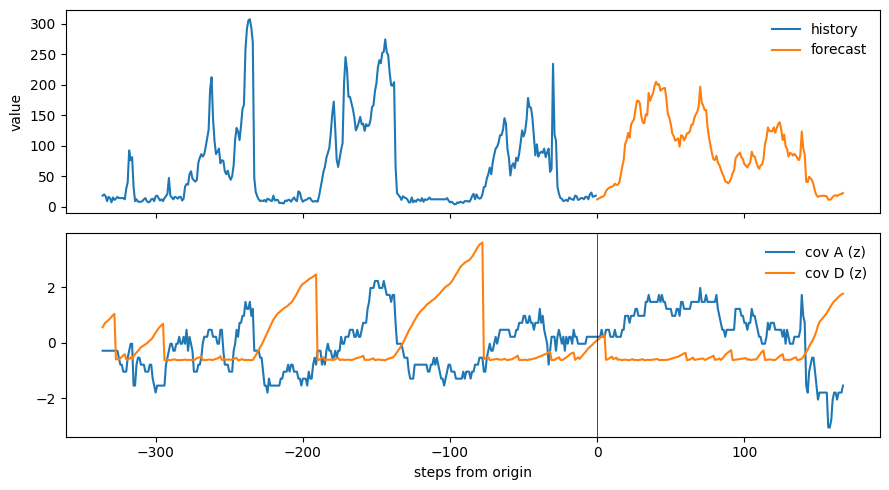

In [ ]:


_F, _S = FOLDS, SEEDS
FOLDS, SEEDS = 1, [0, 5, 9]
best_e, tab = choose_epochs("dec+f2", (6, 20))
FOLDS, SEEDS = _F, _S
display(tab)
FIXED_E = best_e


FINAL_ARM = "dec+f2"
FINAL_EPOCHS = FIXED_E if FIXED_E else 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)
plot_forecast(forecast, cov=ARMS[FINAL_ARM].cont)

#higher

In [ ]:
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"    # autoformer | linhead (baseline + linear covariate head) | dlinear
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 48                  # model width
    heads: int = 8
    el: int = 2                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    delay_band: bool = True     # restrict delays to [min_lag, L//2] (False reproduces v1 behaviour)
    min_lag: int = 8            # smallest delay; choose from the ACF diagnostics (very short lags only measure smoothness)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept; confirm with CELL 5b
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = True        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = True       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 2           # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False
    use_ac: bool = True         # False = Auto-Correlation removed (ablation only; NOT a submittable model)
    use_decomp: bool = True     # False = series decomposition removed (ablation only)


In [ ]:

BASE = Cfg()
ARMS = {"dec+f2":        replace(BASE, cov="dec", fourier=2)
}
prep(geometry(0)[0])
print("parameter counts (the script's own count is the one to declare):")
for name, c in ARMS.items():
    m = build(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:15s} {count(m):6d}")

parameter counts (the script's own count is the one to declare):
  dec+f2           42784


,epochs,sel_RMSE,sd
0,6,50.370,1.140
1,20,50.627,1.645


saved forecast_168.txt (168 values, first=7.06, last=19.33, zeros=0)
declare P = 42784 (sum over 1 model(s)); refit epochs = 6.

 output:7.0625,7.7910,8.7650,10.7603,11.1174,12.8744,16.3802,19.1933,21.3931,24.0590,24.9404,25.9613,28.8626,28.6788,28.9788,31.6995,35.4982,41.4570,47.8476,65.1319,75.9860,83.6760,81.7640,100.0868,107.9435,112.7192,130.1424,133.7816,142.2154,138.9487,129.9603,125.0139,117.2485,140.5604,138.7803,166.1223,157.2572,164.5845,165.1597,168.2826,171.1931,175.5680,192.6058,192.8994,211.9885,216.0068,221.2714,196.3117,163.6653,152.3299,143.0440,131.3662,129.3138,125.5147,129.7179,129.1697,114.9490,134.5259,131.3791,123.9662,130.5087,122.1317,117.0856,124.6373,136.7322,142.8999,147.3145,168.9542,187.0458,209.5732,250.0394,200.5301,190.6646,182.6935,200.7424,160.5657,134.2717,114.8583,102.2914,93.0804,95.6189,99.9029,75.3960,66.7905,64.0234,52.0702,51.1593,42.6933,39.1947,35.6366,36.8717,39.6474,45.7564,48.0210,62.6047,61.7530,58.8976,56.2131,49.9232,49.7748,47.3794,47

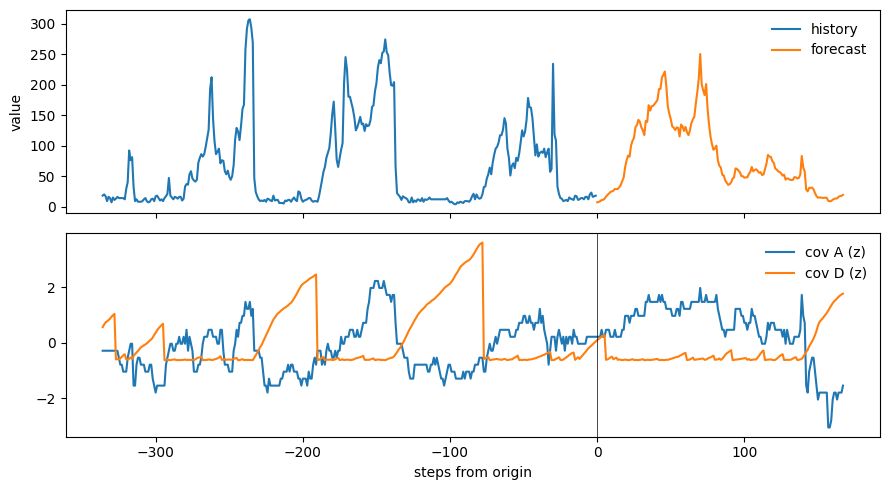

In [ ]:


_F, _S = FOLDS, SEEDS
FOLDS, SEEDS = 1, [0, 5, 9]
best_e, tab = choose_epochs("dec+f2", (6, 20))
FOLDS, SEEDS = _F, _S
display(tab)
FIXED_E = best_e


FINAL_ARM = "dec+f2"
FINAL_EPOCHS = FIXED_E if FIXED_E else 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)
plot_forecast(forecast, cov=ARMS[FINAL_ARM].cont)

In [ ]:

def screen_covariates(nsamp=300, seed=0):
    end = geometry(FOLDS - 1)[0]
    rng = np.random.default_rng(seed)
    origins = rng.integers(max(336, 1), end - H, nsamp)
    res, cv, ct = [], [], []
    for a in origins:
        f = base_forecasts(y[:a])["ACF shrink"]
        res.append(y[a:a + H] - f)
        cv.append(C[a:a + H])
        ct.append(cat_id[a:a + H])
    r, cv, ct = np.concatenate(res), np.concatenate(cv), np.concatenate(ct)
    df_ = pd.DataFrame(cv, columns=list(CONT))
    out = pd.DataFrame({"pearson": df_.corrwith(pd.Series(r)),
                        "spearman": df_.corrwith(pd.Series(r), method="spearman")}).round(3)
    gm = r.mean()
    eta2 = sum(((ct == g).sum() * (r[ct == g].mean() - gm) ** 2) for g in np.unique(ct)) / ((r - gm) ** 2).sum()
    print(f"design region = first {end} steps; {nsamp} random origins x {H} future steps")
    display(out)
    print(f"category (G-J) eta^2 vs baseline residual: {eta2:.3f}")
    print("top-2 by |spearman|:", list(out.spearman.abs().sort_values(ascending=False).index[:2]),
          "| current Cfg.cont:", BASE.cont)
    return out


_ = screen_covariates()


design region = first 30216 steps; 300 random origins x 168 future steps


,pearson,spearman
A,0.217,0.320
B,-0.046,0.037
C,-0.108,-0.174
D,-0.260,-0.368
E,0.054,0.062
F,-0.049,0.005


category (G-J) eta^2 vs baseline residual: 0.074
top-2 by |spearman|: ['D', 'A'] | current Cfg.cont: ('A', 'D')


# untied


In [ ]:
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"    # autoformer | linhead (baseline + linear covariate head) | dlinear
    L: int = 96                 # history window
    LBL: int = 48               # label (overlap) length given to the decoder
    d: int = 48                  # model width
    heads: int = 8
    el: int = 2                 # encoder layers
    dl: int = 1                 # decoder layers
    k: int = 25                 # moving-average kernel
    drop: float = 0.1
    c: float = 2.0              # number of delays k = c * log(length)
    delay_band: bool = True     # restrict delays to [min_lag, L//2] (False reproduces v1 behaviour)
    min_lag: int = 8            # smallest delay; choose from the ACF diagnostics (very short lags only measure smoothness)
    cov: str = "dec"            # none | enc | dec | both  (where covariates enter)
    cont: tuple = ("A", "D")    # continuous covariates kept; confirm with CELL 5b
    use_cat: bool = True        # embed the one-hot G-J block as a 4-way category
    emb: int = 2
    fourier: int = 2            # harmonics of the 24-step period (24 and 12)
    period: float = 24.0
    residual: bool = True       # learn a residual on top of the learnable baseline
    slow: bool = False          # blend the baseline level with the mean of the last W_slow steps
    W_slow: int = 720
    M: int = 12                 # recent values averaged into the baseline's "now"
    phi0: float = 0.966         # initial per-step memory (from the ACF)
    alpha0: float = 0.3         # initial smoothing rate for "now"
    tie_dec: bool = False        # decoder self- and cross-Auto-Correlation share weights
    share_qk: bool = False       # one projection for Q and K
    proj_out: bool = False      # output projection inside Auto-Correlation
    ff_mult: int = 2           # feed-forward width multiple
    bias: bool = False          # biases in the Auto-Correlation projections
    norm_layers: bool = False
    use_ac: bool = True         # False = Auto-Correlation removed (ablation only; NOT a submittable model)
    use_decomp: bool = True     # False = series decomposition removed (ablation only)


In [ ]:

BASE = replace(Cfg(), tie_dec=False, share_qk=False, proj_out=True, ff_mult=2, bias=True)

ARMS = {"dec+f2":        replace(BASE, cov="dec", fourier=2)
}


def base_forecasts(h):
    P = int(BASE.period)
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m),
            "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m),
            f"seasonal naive {P}": np.tile(h[-P:], math.ceil(H / P))[:H],
            "seasonal naive 168": h[-168:].copy()}


BASE_NAMES = list(base_forecasts(y[:500]))

In [ ]:

prep(geometry(0)[0])
for name, c in ARMS.items():
    m = build(c).to(DEV)
    args, _ = batch(blocks(geometry(0)[1], c)[:2], c)
    assert m(*args).shape == (2, H), name
    print(f"  {name:15s} {count(m):6d}")

  dec+f2           66593


In [ ]:


def geometry(k):
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0


def tf(v):
    return np.log1p(v) if TARGET == "log1p" else v


def inv(z):

    z = z * SD + MU
    return torch.expm1(z.clamp(max=20.0)) if TARGET == "log1p" else z


def prep(fit_end):
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    yt = tf(y)
    MU, SD = float(yt[:fit_end].mean()), float(yt[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (yt - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)   # for the slow level
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)



T = 43656 | N = 43824


,epochs,sel_RMSE,sd
0,6,51.189,2.732
1,10,50.696,1.273


saved forecast_168.txt (168 values, first=13.30, last=23.38, zeros=0)
declare P = 66593 (sum over 1 model(s)); refit epochs = 10.

 output:13.3021,15.2386,17.5786,21.1583,22.0051,24.1297,29.7673,34.4533,36.8905,39.4301,43.3078,43.3839,46.0793,44.7749,45.1838,46.9376,52.0558,59.4577,68.3636,90.1603,98.6697,111.5737,104.9830,124.9984,130.5479,134.7393,154.0770,151.6235,148.0439,140.9923,138.4348,136.3192,132.3910,153.6752,155.0340,191.5890,193.5567,205.4887,211.5113,226.1539,249.9881,262.3285,263.4462,272.0194,282.9089,280.1471,284.6957,274.6703,238.9617,236.2563,225.0754,206.1380,194.0356,186.1167,194.2768,190.9112,176.5030,205.4924,199.1405,180.1380,184.3613,203.3123,216.9459,225.7457,227.9955,227.4785,238.6796,248.0984,255.3529,271.4343,335.1209,276.5097,272.6288,261.9154,288.2555,240.8817,195.7295,159.3487,134.9205,120.4417,116.7438,118.4574,90.7982,80.2750,73.5799,62.8340,60.1476,50.0750,48.0363,46.8219,48.3280,49.9491,63.2574,69.1760,92.2710,90.5168,90.1824,85.0744,77.4742,78.1399,

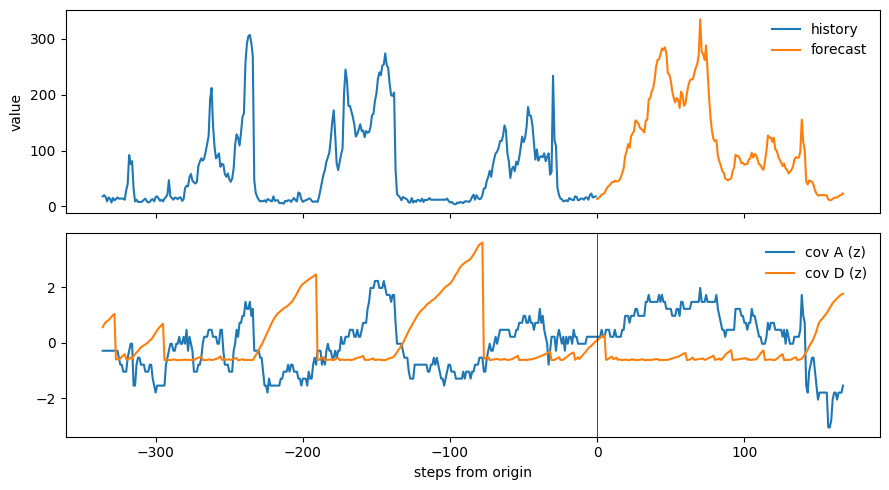

In [ ]:


_F, _S = FOLDS, SEEDS
FOLDS, SEEDS = 1, [0, 5, 9]
best_e, tab = choose_epochs("dec+f2", (6, 10))
FOLDS, SEEDS = _F, _S
display(tab)
FIXED_E = best_e


FINAL_ARM = "dec+f2"
FINAL_EPOCHS = FIXED_E if FIXED_E else 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)
plot_forecast(forecast, cov=ARMS[FINAL_ARM].cont)

# validation

In [ ]:
# %% CELL 1
import math, os, time
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
try:
    from IPython.display import display
except ImportError:
    display = print

MODE = os.environ.get("T2_MODE", "full")
DATA_DIR = os.environ.get("T2_DATA_DIR", "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data")
THREADS = 2
TARGET = "raw"
OVERRIDES = dict(seeds=[0, 1, 2])
FIXED_E = None

PRESETS = {
    "debug": dict(cap=3500, nb=3, folds=1, seeds=[0, 1], epochs=2, patience=1, bs=16, stride=8, device="cpu"),
    "full": dict(cap=None, nb=20, folds=3, seeds=[0, 1, 2, 3, 4], epochs=15, patience=4, bs=64, stride=2,
                 device="auto"),
}
SETTINGS = dict(PRESETS[MODE])
SETTINGS.update(OVERRIDES)
DEV = torch.device("cpu") if SETTINGS["device"] == "cpu" else torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(THREADS)
H, LR = 168, 2e-3
NB, FOLDS, SEEDS = SETTINGS["nb"], SETTINGS["folds"], SETTINGS["seeds"]
EPOCHS, PATIENCE, BS, STRIDE = SETTINGS["epochs"], SETTINGS["patience"], SETTINGS["bs"], SETTINGS["stride"]
print(f"mode={MODE} device={DEV} target={TARGET} folds={FOLDS} blocks/fold={NB} seeds={SEEDS}")


# %% CELL 2
CONT = "ABCDEF"
tr = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv"))
ex = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv"))
tr = tr.sort_values("time_idx").reset_index(drop=True)
ex = ex.sort_values("time_idx").reset_index(drop=True)
assert tr["time_idx"].iloc[0] == 1 and (tr["time_idx"].diff().dropna() == 1).all(), "student_train time_idx must run 1..T"
assert (ex["time_idx"].to_numpy() == np.arange(1, len(ex) + 1)).all(), "external file must run time_idx 1..N"
assert MODE != "full" or (len(tr) == 43656 and len(ex) == 43824), "unexpected file sizes"
y = tr["value"].to_numpy(np.float64)
if SETTINGS["cap"]:
    y = y[:SETTINGS["cap"]]
    ex = ex.iloc[:len(y) + H]
T, N = len(y), len(ex)
assert N == T + H, "external file must cover the history plus the 168 forecast steps"
cat_cols = [f"feature_{c}" for c in "GHIJ"]
assert (ex[cat_cols].sum(axis=1) == 1).all()
C = ex[[f"feature_{c}" for c in CONT]].to_numpy(np.float64)
cat_id = ex[cat_cols].to_numpy().argmax(1)


def geometry(k):
    rep0 = T - k * NB * H - NB * H
    return rep0 - NB * H, rep0


def tf(v):
    return np.log1p(v) if TARGET == "log1p" else v


def inv(z):
    z = z * SD + MU
    return torch.expm1(z.clamp(max=20.0)) if TARGET == "log1p" else z


def prep(fit_end):
    global FIT_END, MU, SD, Y, Cn, K, CS
    FIT_END = fit_end
    yt = tf(y)
    MU, SD = float(yt[:fit_end].mean()), float(yt[:fit_end].std())
    yn = np.zeros(N)
    yn[:T] = (yt - MU) / SD
    cm, cs = C[:fit_end].mean(0), C[:fit_end].std(0) + 1e-6
    Y = torch.tensor(yn, dtype=torch.float32, device=DEV)
    CS = torch.cat([torch.zeros(1, dtype=torch.float64),
                    torch.cumsum(torch.tensor(yn, dtype=torch.float64), 0)]).to(DEV)
    Cn = torch.tensor((C - cm) / cs, dtype=torch.float32, device=DEV)
    K = torch.tensor(cat_id, device=DEV)


print("T =", T, "| N =", N)


# %% CELL 3
@dataclass(frozen=True)
class Cfg:
    arch: str = "autoformer"
    L: int = 96
    LBL: int = 48
    d: int = 8
    heads: int = 2
    el: int = 1
    dl: int = 1
    k: int = 25
    drop: float = 0.1
    c: float = 2.0
    delay_band: bool = True
    min_lag: int = 8
    cov: str = "dec"
    cont: tuple = ("A", "D")
    use_cat: bool = True
    emb: int = 2
    fourier: int = 2
    period: float = 24.0
    residual: bool = True
    slow: bool = False
    W_slow: int = 720
    M: int = 12
    phi0: float = 0.966
    alpha0: float = 0.3
    tie_dec: bool = True
    share_qk: bool = True
    proj_out: bool = False
    ff_mult: int = 1
    bias: bool = False
    norm_layers: bool = False
    use_ac: bool = True
    use_decomp: bool = True


def sinus(n, d):
    p = torch.arange(n)[:, None].float()
    i = torch.arange(0, d, 2)[None].float()
    a = p / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = a.sin(), a.cos()
    return pe[None]


def logit(p):
    return math.log(p / (1 - p))


class Decomp(nn.Module):
    def __init__(s, k, on=True):
        super().__init__()
        s.k, s.on = k, on

    def forward(s, x):
        if not s.on:
            return x, torch.zeros_like(x)
        q = s.k // 2
        t = F.avg_pool1d(F.pad(x.transpose(1, 2), (q, q), mode="replicate"), s.k, 1).transpose(1, 2)
        return x - t, t


class AutoCorr(nn.Module):
    def __init__(s, c):
        super().__init__()
        d = c.d
        s.h, s.c, s.band, s.lo, s.use = c.heads, c.c, c.delay_band, c.min_lag, c.use_ac
        if not s.use:
            return
        s.wq = nn.Linear(d, d, bias=c.bias)
        s.wk = None if c.share_qk else nn.Linear(d, d, bias=c.bias)
        s.wv = nn.Linear(d, d, bias=c.bias)
        s.wo = nn.Linear(d, d) if c.proj_out else None
        s.log_tau = nn.Parameter(torch.zeros(()))

    def forward(s, q, k, v):
        if not s.use:
            return torch.zeros_like(q)
        B, L, D = q.shape
        q, k, v = s.wq(q), (s.wq if s.wk is None else s.wk)(k), s.wv(v)
        if k.shape[1] < L:
            p = (0, 0, 0, L - k.shape[1])
            k, v = F.pad(k, p), F.pad(v, p)
        else:
            k, v = k[:, :L], v[:, :L]
        r = lambda z: z.reshape(B, L, s.h, D // s.h).permute(0, 2, 3, 1)
        corr = torch.fft.irfft(torch.fft.rfft(r(q)) * torch.conj(torch.fft.rfft(r(k))), n=L)
        score = corr.mean((1, 2)) / L
        kk = max(1, int(s.c * math.log(L)))
        if s.band:
            lo, hi = s.lo, L // 2
            mask = torch.full((L,), float("-inf"), device=q.device)
            mask[lo:hi + 1] = 0.0
            score = score + mask
            kk = min(kk, hi - lo + 1)
        w, idx = score.topk(kk, -1)
        w = torch.softmax(w / torch.exp(s.log_tau), -1)
        t = torch.arange(L, device=q.device)
        gi = (t[None, None] - idx[:, :, None]) % L
        g = torch.gather(v[:, None].expand(B, kk, L, D), 2, gi[..., None].expand(-1, -1, -1, D))
        out = (w[:, :, None, None] * g).sum(1)
        return out if s.wo is None else s.wo(out)


class FF(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n = nn.Sequential(nn.Linear(c.d, c.ff_mult * c.d), nn.GELU(), nn.Dropout(c.drop),
                            nn.Linear(c.ff_mult * c.d, c.d))

    def forward(s, x):
        return s.n(x)


class Enc(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a, s.f, s.dc, s.dr = AutoCorr(c), FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop)

    def forward(s, x):
        x, _ = s.dc(x + s.dr(s.a(x, x, x)))
        x, _ = s.dc(x + s.dr(s.f(x)))
        return x


class Dec(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.a1 = AutoCorr(c)
        s.a2 = s.a1 if c.tie_dec else AutoCorr(c)
        s.f, s.dc, s.dr, s.proj = FF(c), Decomp(c.k, c.use_decomp), nn.Dropout(c.drop), nn.Linear(c.d, 1)

    def forward(s, x, e):
        x, t1 = s.dc(x + s.dr(s.a1(x, x, x)))
        x, t2 = s.dc(x + s.dr(s.a2(x, e, e)))
        x, t3 = s.dc(x + s.dr(s.f(x)))
        return x, s.proj(t1 + t2 + t3)


class Feats(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.nf, s.P = c, c.fourier, c.period
        s.emb = nn.Embedding(4, c.emb) if (c.cov != "none" and c.use_cat) else None
        s.register_buffer("n", torch.arange(1, c.fourier + 1, dtype=torch.float64))

    def forward(s, cont, cat, t, use):
        parts = []
        if use:
            parts.append(cont)
            if s.emb is not None:
                parts.append(s.emb(cat))
        if s.nf:
            tm = torch.remainder(t.double(), s.P)
            ph = (2 * math.pi * tm[..., None] * s.n / s.P).float()
            parts += [ph.sin(), ph.cos()]
        return torch.cat(parts, -1) if parts else None


class Baseline(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.phi = nn.Parameter(torch.tensor(logit(c.phi0)))
        s.alpha = nn.Parameter(torch.tensor(logit(c.alpha0)))
        s.level = nn.Parameter(torch.zeros(()))
        if c.slow:
            s.gamma = nn.Parameter(torch.tensor(-3.0))
        s.register_buffer("steps", torch.arange(1, H + 1).float())

    def forward(s, yE, slow):
        c = s.c
        a = torch.sigmoid(s.alpha)
        age = torch.arange(c.M - 1, -1, -1, device=yE.device, dtype=yE.dtype)
        w = (1 - a) ** age
        w = w / w.sum()
        now = (w * yE[:, -c.M:]).sum(1, keepdim=True)
        lev = s.level
        if c.slow:
            g = torch.sigmoid(s.gamma)
            lev = (1 - g) * s.level + g * slow[:, None]
        return lev + torch.sigmoid(s.phi) ** s.steps[None] * (now - lev)


def cov_width(c):
    return (len(c.cont) + (c.emb if c.use_cat else 0)) if c.cov != "none" else 0


class Net(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c, s.feat = c, Feats(c)
        w = cov_width(c)
        ein = 1 + (w if c.cov in ("enc", "both") else 0) + 2 * c.fourier
        din = 1 + (w if c.cov in ("dec", "both") else 0) + 2 * c.fourier
        s.ei, s.di = nn.Linear(ein, c.d), nn.Linear(din, c.d)
        s.enc = nn.ModuleList(Enc(c) for _ in range(c.el))
        s.dec = nn.ModuleList(Dec(c) for _ in range(c.dl))
        norm = (lambda: nn.LayerNorm(c.d)) if c.norm_layers else (lambda: nn.Identity())
        s.en, s.dn = norm(), norm()
        s.out, s.dc = nn.Linear(c.d, 1), Decomp(c.k, c.use_decomp)
        s.register_buffer("pe", sinus(max(c.L, c.LBL + H), c.d))
        s.base = Baseline(c) if c.residual else None
        if c.residual:
            nn.init.zeros_(s.out.weight)
            nn.init.zeros_(s.out.bias)
            for l in s.dec:
                nn.init.zeros_(l.proj.weight)
                nn.init.zeros_(l.proj.bias)

    def forward(s, yE, cE, kE, tE, cD, kD, tD, slow):
        c, B = s.c, yE.shape[0]
        z = yE.unsqueeze(-1)
        seas, trend = s.dc(z)
        zs = torch.cat([seas[:, -c.LBL:], torch.zeros(B, H, 1, device=z.device)], 1)
        fE = s.feat(cE, kE, tE, c.cov in ("enc", "both"))
        fD = s.feat(cD, kD, tD, c.cov in ("dec", "both"))
        xe = z if fE is None else torch.cat([z, fE], -1)
        xd = zs if fD is None else torch.cat([zs, fD], -1)
        e = s.ei(xe) + s.pe[:, :c.L]
        for l in s.enc:
            e = l(e)
        e = s.en(e)
        x = s.di(xd) + s.pe[:, :c.LBL + H]
        if c.residual:
            tr_ = torch.zeros(B, c.LBL + H, 1, device=z.device)
        else:
            tr_ = torch.cat([trend[:, -c.LBL:], z.mean(1, keepdim=True).expand(-1, H, -1)], 1)
        for l in s.dec:
            x, t = l(x, e)
            tr_ = tr_ + t
        x = s.dn(x)
        out = (s.out(x) + tr_)[:, -H:, 0]
        return out + s.base(yE, slow) if c.residual else out


def build(c):
    return Net(c)


# %% CELL 4
def batch(st, c):
    ar = lambda n: torch.arange(n, device=DEV)
    ie = st[:, None] + ar(c.L)
    idd = st[:, None] + c.L - c.LBL + ar(c.LBL + H)
    tg = st[:, None] + c.L + ar(H)
    ci = torch.tensor([CONT.index(x) for x in c.cont], dtype=torch.long, device=DEV)
    e = st + c.L
    lo = (e - c.W_slow).clamp(min=0)
    slow = ((CS[e] - CS[lo]) / (e - lo)).float()
    args = (Y[ie], Cn[ie].index_select(-1, ci), K[ie], ie,
            Cn[idd].index_select(-1, ci), K[idd], idd, slow)
    return args, Y[tg]


def blocks(a0, c):
    return torch.tensor([a0 + H * j - c.L for j in range(NB)], device=DEV)


@torch.no_grad()
def evaluate(m, starts, c):
    m.eval()
    P, Tg = [], []
    for i in range(0, len(starts), 256):
        args, tg = batch(starts[i:i + 256], c)
        P.append(m(*args))
        Tg.append(tg)
    return inv(torch.cat(P)).clamp(min=0), inv(torch.cat(Tg))


def metrics(p, t):
    p = torch.as_tensor(p, dtype=torch.float64).flatten()
    t = torch.as_tensor(t, dtype=torch.float64).flatten()
    e = p - t
    den = p.abs() + t.abs()
    smape = torch.where(den == 0, torch.zeros_like(den), 2 * e.abs() / den.clamp(min=1e-12))
    mse = e.pow(2).mean().item()
    return dict(MSE=mse, RMSE=math.sqrt(mse), MAE=e.abs().mean().item(), sMAPE=100 * smape.mean().item())


def rmse_t(p, t):
    return metrics(p, t)["RMSE"]


def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


LABELS = {
    "ei": "encoder input layer", "di": "decoder input layer", "feat": "category embedding",
    "enc.0.a": "encoder Auto-Correlation", "enc.0.f": "encoder feed-forward",
    "dec.0.a1": "decoder Auto-Correlation (self and cross, tied)", "dec.0.f": "decoder feed-forward",
    "dec.0.proj": "decoder trend projection", "out": "output projection", "base": "learnable baseline",
}


def param_table(m):
    rows, run = [], 0
    for n, p in m.named_parameters():
        if p.requires_grad:
            run += p.numel()
            rows.append((n, tuple(p.shape), p.numel(), run))
    print(f"{'parameter':30s}{'shape':10s}{'count':>7s}{'running total':>15s}")
    for n, s, k, r in rows:
        print(f"{n:30s}{str(s):10s}{k:7d}{r:15d}")
    groups = {}
    for n, s, k, r in rows:
        parts = n.split(".")
        key = ".".join(parts[:3]) if parts[0] in ("enc", "dec") else parts[0]
        groups[key] = groups.get(key, 0) + k
    print(f"\n{'component':52s}{'count':>7s}{'running total':>15s}")
    run = 0
    for key, k in groups.items():
        run += k
        print(f"{LABELS.get(key, key):52s}{k:7d}{run:15d}")
    assert run == count(m)
    print(f"\nTOTAL trainable parameters: {run}")
    print("zero-parameter buffers:", [n for n, _ in m.named_buffers()])


def fit(c, seed, epochs, val=None):
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = build(c).to(DEV)
    base_params = list(m.base.parameters()) if getattr(m, "base", None) is not None else []
    ids = {id(p) for p in base_params}
    rest = [p for p in m.parameters() if id(p) not in ids]
    groups = [dict(params=rest, lr=LR, weight_decay=1e-4)]
    if base_params:
        groups.append(dict(params=base_params, lr=LR * 5, weight_decay=0.0))
    opt = torch.optim.AdamW(groups)
    n_win = FIT_END - c.L - H + 1
    total = epochs * math.ceil(math.ceil(n_win / STRIDE) / BS) + 1
    sch = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: 0.5 * (1 + math.cos(math.pi * min(i, total) / total)))
    best, best_ep, bad, run, state = float("inf"), 0, 0, 0, None
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        off = int(torch.randint(0, STRIDE, (1,)))
        starts = torch.arange(off, n_win, STRIDE, device=DEV)
        perm = starts[torch.randperm(len(starts), device=DEV)]
        for i in range(0, len(perm), BS):
            args, tg = batch(perm[i:i + BS], c)
            loss = F.mse_loss(m(*args), tg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            sch.step()
        if val is not None:
            r = rmse_t(*evaluate(m, val, c))
            if r < best:
                best, best_ep, bad = r, ep, 0
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if state is not None:
        m.load_state_dict(state)
    return m, (best_ep if val is not None else epochs), run


BASE = Cfg()
ARMS = {"dec+f2": replace(BASE, cov="dec", fourier=2)}


def base_forecasts(h):
    P = int(BASE.period)
    m, phi, now = h.mean(), float(np.corrcoef(h[:-1], h[1:])[0, 1]), h[-3:].mean()
    return {"global mean": np.full(H, m),
            "ACF shrink": m + phi ** np.arange(1, H + 1) * (now - m),
            f"seasonal naive {P}": np.tile(h[-P:], math.ceil(H / P))[:H],
            "seasonal naive 168": h[-168:].copy()}


BASE_NAMES = list(base_forecasts(y[:500]))


def choose_epochs(name, cands=(6, 10, 20)):
    c = ARMS[name]
    res = {e: [] for e in cands}
    for k in range(FOLDS):
        sel0, _ = geometry(k)
        prep(sel0)
        sel = blocks(sel0, c)
        for sd in SEEDS:
            for e in cands:
                m, _, _ = fit(c, sd, e)
                res[e].append(metrics(*evaluate(m, sel, c)))
    rows = []
    for e in cands:
        d_ = pd.DataFrame(res[e])
        rows.append(dict(epochs=e, **d_.mean().to_dict(),
                         RMSE_sd=d_["RMSE"].std(ddof=1) if len(d_) > 1 else np.nan))
    tab = pd.DataFrame(rows).round(3)
    return int(tab.loc[tab.RMSE.idxmin(), "epochs"]), tab


def validate(name, epochs, seeds=None, folds=None):
    c = ARMS[name]
    seeds = SEEDS if seeds is None else seeds
    folds = FOLDS if folds is None else folds
    preds, tgts, base = {sd: [] for sd in seeds}, [], {n: [] for n in BASE_NAMES}
    for k in range(folds):
        sel0, rep0 = geometry(k)
        prep(sel0)
        rep = blocks(rep0, c)
        fc = [base_forecasts(y[:rep0 + H * j]) for j in range(NB)]
        for n in BASE_NAMES:
            base[n].append(torch.tensor(np.stack([f[n] for f in fc]), dtype=torch.float32))
        for i, sd in enumerate(seeds):
            m, _, _ = fit(c, sd, epochs)
            p, t = evaluate(m, rep, c)
            preds[sd].append(p.cpu())
            if i == 0:
                tgts.append(t.cpu())
    tg = torch.cat(tgts)
    rows = [dict(arm=f"baseline: {n}", P=0, **metrics(torch.cat(base[n]).clamp(min=0), tg)) for n in BASE_NAMES]
    per = pd.DataFrame([metrics(torch.cat(preds[sd]), tg) for sd in seeds])
    rows.append(dict(arm=name, P=count(build(c)), **per.mean().to_dict(),
                     RMSE_sd=per["RMSE"].std(ddof=1) if len(seeds) > 1 else np.nan))
    return pd.DataFrame(rows).round(3), per.round(3)


def final_forecast(c, seeds, epochs):
    assert c.arch == "autoformer" and c.use_ac and c.use_decomp, \
        "submitted model must be an Autoformer with Series Decomposition AND Auto-Correlation (req. 2.4.1)"
    prep(T)
    preds, P = [], 0
    for sd in seeds:
        m, _, _ = fit(c, sd, epochs)
        p, _ = evaluate(m, torch.tensor([T - c.L], device=DEV), c)
        preds.append(p[0].cpu().numpy())
        P += count(m)
    out = np.clip(np.mean(preds, 0), 0, None)
    assert out.shape == (H,)
    txt = ",".join(f"{v:.4f}" for v in out)
    open("forecast_168.txt", "w").write(txt)
    print(f"saved forecast_168.txt ({H} values, first={out[0]:.2f}, last={out[-1]:.2f}, zeros={(out == 0).sum()})")
    print(f"declare P = {P} (sum over {len(seeds)} model(s)); refit epochs = {epochs * len(seeds)}")
    print("\noutput:" + txt)
    return out


def predict_test(out):
    path = os.path.join(DATA_DIR, "student_test.csv")
    if not os.path.exists(path):
        print("student_test.csv not found in", DATA_DIR)
        return None
    if T != 43656:
        print("skipped: student_test.csv only applies to the full data (MODE='full')")
        return None
    te = pd.read_csv(path).sort_values("time_idx").reset_index(drop=True)
    idx = np.arange(T + 1, T + H + 1)
    assert len(te) == H and (te["time_idx"].to_numpy() == idx).all(), "student_test.csv time_idx != 43657..43824"
    pd.DataFrame({"time_idx": idx, "value": out}).to_csv("forecast_168.csv", index=False)
    print("wrote forecast_168.csv (time_idx 43657..43824)")
    if "value" in te.columns and te["value"].notna().all():
        m = metrics(out, te["value"].to_numpy(float))
        print("metrics on student_test.csv:", {k: round(v, 3) for k, v in m.items()})
        return m
    print("student_test.csv contains no target values, so no metrics can be computed locally; "
          "test-set scores come only from the leaderboard")
    return None


def plot_forecast(out, cov=("A", "D"), back=336):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(range(-back, 0), y[-back:], label="history")
    ax[0].plot(range(0, H), out, label="forecast")
    ax[0].set_ylabel("value")
    ax[0].legend(frameon=False)
    for cname in cov:
        j = CONT.index(cname)
        v = C[T - back:T + H, j]
        ax[1].plot(range(-back, H), (v - v.mean()) / (v.std() + 1e-9), label=f"cov {cname} (z)")
    ax[1].axvline(0, color="k", lw=0.5)
    ax[1].legend(frameon=False)
    ax[1].set_xlabel("steps from origin")
    fig.tight_layout()
    fig.savefig("forecast_plot.png", dpi=130)
    plt.show()


# %% CELL 5
prep(geometry(0)[0])
m5 = build(ARMS["dec+f2"]).to(DEV)
args, _ = batch(blocks(geometry(0)[1], ARMS["dec+f2"])[:2], ARMS["dec+f2"])
assert m5(*args).shape == (2, H)
param_table(m5)


# %% CELL 5b
def screen_covariates(nsamp=300, seed=0):
    end = geometry(FOLDS - 1)[0]
    rng = np.random.default_rng(seed)
    origins = rng.integers(max(336, 1), end - H, nsamp)
    res, cv, ct = [], [], []
    for a in origins:
        f = base_forecasts(y[:a])["ACF shrink"]
        res.append(y[a:a + H] - f)
        cv.append(C[a:a + H])
        ct.append(cat_id[a:a + H])
    r, cv, ct = np.concatenate(res), np.concatenate(cv), np.concatenate(ct)
    df_ = pd.DataFrame(cv, columns=list(CONT))
    out = pd.DataFrame({"pearson": df_.corrwith(pd.Series(r)),
                        "spearman": df_.corrwith(pd.Series(r), method="spearman")}).round(3)
    gm = r.mean()
    eta2 = sum(((ct == g).sum() * (r[ct == g].mean() - gm) ** 2) for g in np.unique(ct)) / ((r - gm) ** 2).sum()
    print(f"design region = first {end} steps; {nsamp} random origins x {H} future steps")
    display(out)
    print(f"category (G-J) eta^2 vs baseline residual: {eta2:.3f}")
    print("top-2 by |spearman|:", list(out.spearman.abs().sort_values(ascending=False).index[:2]),
          "| current Cfg.cont:", BASE.cont)
    return out


_ = screen_covariates()


# %% CELL 6a
CAND_EPOCHS = (6, 10, 20)
_F, _S = FOLDS, SEEDS
FOLDS, SEEDS = 1, [0, 1, 2]
best_e, tab = choose_epochs("dec+f2", CAND_EPOCHS)
FOLDS, SEEDS = _F, _S
display(tab)
FIXED_E = best_e
print("selected epochs:", FIXED_E)


# %% CELL 6b
val_table, val_per_seed = validate("dec+f2", FIXED_E)
print("\nreport blocks, pooled over folds (model = mean over seeds)")
display(val_table)
print("per-seed metrics")
display(val_per_seed)
val_table.to_csv("task2_validation_metrics.csv", index=False)


# %% CELL 7
FINAL_ARM = "dec+f2"
FINAL_EPOCHS = FIXED_E if FIXED_E else 10
forecast = final_forecast(ARMS[FINAL_ARM], [0], FINAL_EPOCHS)
test_metrics = predict_test(forecast)
plot_forecast(forecast, cov=ARMS[FINAL_ARM].cont)

mode=full device=cuda target=raw folds=3 blocks/fold=20 seeds=[0, 1, 2]
T = 43656 | N = 43824
parameter                     shape       count  running total
feat.emb.weight               (4, 2)          8              8
ei.weight                     (8, 5)         40             48
ei.bias                       (8,)            8             56
di.weight                     (8, 9)         72            128
di.bias                       (8,)            8            136
enc.0.a.log_tau               ()              1            137
enc.0.a.wq.weight             (8, 8)         64            201
enc.0.a.wv.weight             (8, 8)         64            265
enc.0.f.n.0.weight            (8, 8)         64            329
enc.0.f.n.0.bias              (8,)            8            337
enc.0.f.n.3.weight            (8, 8)         64            401
enc.0.f.n.3.bias              (8,)            8            409
dec.0.a1.log_tau              ()              1            410
dec.0.a1.wq.weight      

,pearson,spearman
A,0.217,0.320
B,-0.046,0.037
C,-0.108,-0.174
D,-0.260,-0.368
E,0.054,0.062
F,-0.049,0.005


category (G-J) eta^2 vs baseline residual: 0.074
top-2 by |spearman|: ['D', 'A'] | current Cfg.cont: ('A', 'D')


,epochs,MSE,RMSE,MAE,sMAPE,RMSE_sd
0,6,3007.909,54.841,44.222,60.378,0.739
1,10,2932.318,54.133,43.811,60.124,1.702
2,20,2919.930,54.029,43.304,58.267,1.103


selected epochs: 20


# from autoformer


In [ ]:
import math, copy, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [ ]:

CSV_PATH  = "/content/drive/MyDrive/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data/student_train.csv"
VALUE_COL = None
TIME_COL  = None

SEQ_LEN, LABEL_LEN, PRED_LEN = 96, 48, 168                       # the leaderboard needs exactly 168
D_MODEL, N_HEADS, E_LAYERS, D_LAYERS, D_FF = 64, 4, 2, 1, 96     # about 92k parameters
MOVING_AVG, FACTOR, DROPOUT = 25, 1, 0.05

EPOCHS, BATCH_SIZE, LR, PATIENCE, SEED = 30, 32, 1e-3, 5, 2021
WEIGHT_DECAY = 1e-2
SEEDS = [0, 1, 2]



In [ ]:
df = pd.read_csv(CSV_PATH, sep=None, engine="python")
vcol = VALUE_COL or ("value" if "value" in df.columns else df.select_dtypes("number").columns[-1])
tcol = TIME_COL or ("time_idx" if "time_idx" in df.columns else None)
if tcol is not None:
    df = df.sort_values(tcol)
series = pd.to_numeric(df[vcol], errors="coerce")
if series.isna().any():
    print(f"interpolating {int(series.isna().sum())} missing values")
    series = series.interpolate(limit_direction="both")
raw = series.to_numpy(dtype=np.float32).reshape(-1, 1)          # [N, 1]
n = len(raw)

n_train, n_test = int(n * 0.7), int(n * 0.2)
n_val = n - n_train - n_test
borders1 = [0, n_train - SEQ_LEN, n - n_test - SEQ_LEN]
borders2 = [n_train, n_train + n_val, n]
assert n_val > PRED_LEN and n_test > PRED_LEN, "series too short for this SEQ_LEN/PRED_LEN"

mean, std = raw[:n_train].mean(), raw[:n_train].std() + 1e-8
scaled = (raw - mean) / std

class WindowSet(torch.utils.data.Dataset):
    def __init__(self, split):
        self.data = torch.tensor(scaled[borders1[split]:borders2[split]])
    def __len__(self):
        return len(self.data) - SEQ_LEN - PRED_LEN + 1
    def __getitem__(self, i):
        x = self.data[i:i + SEQ_LEN]
        y = self.data[i + SEQ_LEN - LABEL_LEN : i + SEQ_LEN + PRED_LEN]   # label part + target
        return x, y

train_set, val_set, test_set = WindowSet(0), WindowSet(1), WindowSet(2)
train_loader = torch.utils.data.DataLoader(train_set, BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = torch.utils.data.DataLoader(val_set,   BATCH_SIZE, shuffle=False)
test_loader  = torch.utils.data.DataLoader(test_set,  BATCH_SIZE, shuffle=False)
print(f"N={n} | windows train/val/test = {len(train_set)}/{len(val_set)}/{len(test_set)}")

N=43656 | windows train/val/test = 30296/4199/8564


In [ ]:
class MovingAvg(nn.Module):
    """Moving average with replicate padding at both ends (keeps length)."""
    def __init__(self, kernel_size, stride=1):
        super().__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)
    def forward(self, x):                                   # [B, L, C]
        pad = (self.kernel_size - 1) // 2
        front = x[:, :1, :].repeat(1, pad, 1)
        end = x[:, -1:, :].repeat(1, pad, 1)
        x = torch.cat([front, x, end], dim=1)
        return self.avg(x.permute(0, 2, 1)).permute(0, 2, 1)

class SeriesDecomp(nn.Module):
    """X_trend = AvgPool(Padding(X)); X_seasonal = X - X_trend."""
    def __init__(self, kernel_size):
        super().__init__()
        self.moving_avg = MovingAvg(kernel_size)
    def forward(self, x):
        trend = self.moving_avg(x)
        return x - trend, trend                             # (seasonal, trend)

class SeasonalLayerNorm(nn.Module):
    """LayerNorm specially designed for the seasonal part (subtract the per-series mean over time)."""
    def __init__(self, channels):
        super().__init__()
        self.layernorm = nn.LayerNorm(channels)
    def forward(self, x):
        x_hat = self.layernorm(x)
        return x_hat - x_hat.mean(dim=1, keepdim=True)

In [ ]:
class AutoCorrelation(nn.Module):
    """R_{Q,K}(tau) via FFT (Wiener-Khinchin); keep top-k delays, aggregate rolled values with softmax weights."""
    def __init__(self, factor=1, dropout=0.1):
        super().__init__()
        self.factor = factor
        self.dropout = nn.Dropout(dropout)

    def _top_k(self, length):
        return max(1, int(self.factor * math.log(length)))

    def delay_agg_training(self, values, corr):             # both [B, H, E, L]
        length = values.shape[-1]
        k = self._top_k(length)
        mean_corr = corr.mean(dim=1).mean(dim=1)             # [B, L]
        index = torch.topk(mean_corr.mean(dim=0), k, dim=-1)[1]       # delays shared across the batch
        weights = torch.stack([mean_corr[:, index[i]] for i in range(k)], dim=-1)
        weights = torch.softmax(weights, dim=-1)             # [B, k]
        out = 0
        for i in range(k):
            pattern = torch.roll(values, -int(index[i]), dims=-1)
            out = out + pattern * weights[:, i].view(-1, 1, 1, 1)
        return out

    def delay_agg_inference(self, values, corr):
        batch, head, channel, length = values.shape
        k = self._top_k(length)
        base = torch.arange(length, device=values.device).view(1, 1, 1, -1).repeat(batch, head, channel, 1)
        mean_corr = corr.mean(dim=1).mean(dim=1)             # [B, L]
        weights, delay = torch.topk(mean_corr, k, dim=-1)    # per-sample delays at inference
        weights = torch.softmax(weights, dim=-1)
        doubled = values.repeat(1, 1, 1, 2)
        out = 0
        for i in range(k):
            idx = base + delay[:, i].view(-1, 1, 1, 1)
            pattern = torch.gather(doubled, dim=-1, index=idx)
            out = out + pattern * weights[:, i].view(-1, 1, 1, 1)
        return out

    def forward(self, queries, keys, values):                # [B, L, H, E], [B, S, H, E], [B, S, H, D]
        B, L, H, E = queries.shape
        S = values.shape[1]
        if L > S:                                            # zero-fill keys/values to length L
            zeros = torch.zeros_like(queries[:, :(L - S)])
            values = torch.cat([values, zeros], dim=1)
            keys = torch.cat([keys, zeros], dim=1)
        else:                                                # truncate to length L
            values, keys = values[:, :L], keys[:, :L]
        q_fft = torch.fft.rfft(queries.permute(0, 2, 3, 1).contiguous(), dim=-1)
        k_fft = torch.fft.rfft(keys.permute(0, 2, 3, 1).contiguous(), dim=-1)
        corr = torch.fft.irfft(q_fft * torch.conj(k_fft), n=L, dim=-1)       # [B, H, E, L]
        v = values.permute(0, 2, 3, 1).contiguous()
        agg = self.delay_agg_training if self.training else self.delay_agg_inference
        return agg(v, corr).permute(0, 3, 1, 2).contiguous()                 # [B, L, H, D]

class AutoCorrelationLayer(nn.Module):
    """Multi-head projections around AutoCorrelation."""
    def __init__(self, d_model, n_heads, factor, dropout):
        super().__init__()
        d_head = d_model // n_heads
        self.inner = AutoCorrelation(factor, dropout)
        self.q_proj = nn.Linear(d_model, d_head * n_heads)
        self.k_proj = nn.Linear(d_model, d_head * n_heads)
        self.v_proj = nn.Linear(d_model, d_head * n_heads)
        self.out_proj = nn.Linear(d_head * n_heads, d_model)
        self.n_heads = n_heads
    def forward(self, q, k, v):
        B, L, _ = q.shape
        S, H = k.shape[1], self.n_heads
        q = self.q_proj(q).view(B, L, H, -1)
        k = self.k_proj(k).view(B, S, H, -1)
        v = self.v_proj(v).view(B, S, H, -1)
        out = self.inner(q, k, v).reshape(B, L, -1)
        return self.out_proj(out)

In [ ]:
class TokenEmbedding(nn.Module):
    def __init__(self, c_in, d_model):
        super().__init__()
        self.conv = nn.Conv1d(c_in, d_model, kernel_size=3, padding=1, padding_mode="circular", bias=False)
        nn.init.kaiming_normal_(self.conv.weight, mode="fan_in", nonlinearity="leaky_relu")
    def forward(self, x):                                    # [B, L, c_in] -> [B, L, d_model]
        return self.conv(x.permute(0, 2, 1)).transpose(1, 2)

class DataEmbedding(nn.Module):
    """Value embedding only. The official code also adds calendar-feature embeddings (no timestamps in this CSV)
    and deliberately omits positional encoding (Auto-Correlation already aligns by delay)."""
    def __init__(self, c_in, d_model, dropout):
        super().__init__()
        self.value = TokenEmbedding(c_in, d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.value(x))

class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, moving_avg, factor, dropout):
        super().__init__()
        self.attn = AutoCorrelationLayer(d_model, n_heads, factor, dropout)
        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1, bias=False)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1, bias=False)
        self.decomp1, self.decomp2 = SeriesDecomp(moving_avg), SeriesDecomp(moving_avg)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        x = x + self.dropout(self.attn(x, x, x))
        x, _ = self.decomp1(x)                               # trend of the encoder is discarded
        y = self.dropout(F.gelu(self.conv1(x.transpose(1, 2))))
        y = self.dropout(self.conv2(y).transpose(1, 2))
        x, _ = self.decomp2(x + y)
        return x

class Encoder(nn.Module):
    def __init__(self, layers, norm):
        super().__init__()
        self.layers, self.norm = nn.ModuleList(layers), norm
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return self.norm(x)

class DecoderLayer(nn.Module):
    def __init__(self, d_model, c_out, n_heads, d_ff, moving_avg, factor, dropout):
        super().__init__()
        self.self_attn = AutoCorrelationLayer(d_model, n_heads, factor, dropout)
        self.cross_attn = AutoCorrelationLayer(d_model, n_heads, factor, dropout)
        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1, bias=False)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1, bias=False)
        self.decomp1, self.decomp2, self.decomp3 = (SeriesDecomp(moving_avg) for _ in range(3))
        self.dropout = nn.Dropout(dropout)
        self.trend_proj = nn.Conv1d(d_model, c_out, kernel_size=3, padding=1,
                                    padding_mode="circular", bias=False)
    def forward(self, x, cross):
        x = x + self.dropout(self.self_attn(x, x, x))
        x, trend1 = self.decomp1(x)
        x = x + self.dropout(self.cross_attn(x, cross, cross))
        x, trend2 = self.decomp2(x)
        y = self.dropout(F.gelu(self.conv1(x.transpose(1, 2))))
        y = self.dropout(self.conv2(y).transpose(1, 2))
        x, trend3 = self.decomp3(x + y)
        trend = self.trend_proj((trend1 + trend2 + trend3).permute(0, 2, 1)).transpose(1, 2)
        return x, trend

class Decoder(nn.Module):
    def __init__(self, layers, norm, projection):
        super().__init__()
        self.layers, self.norm, self.projection = nn.ModuleList(layers), norm, projection
    def forward(self, x, cross, trend):
        for layer in self.layers:
            x, residual_trend = layer(x, cross)
            trend = trend + residual_trend                   # accumulate trend across layers
        return self.projection(self.norm(x)), trend

class Autoformer(nn.Module):
    def __init__(self, seq_len, label_len, pred_len, c_in=1, c_out=1, d_model=512, n_heads=8,
                 e_layers=2, d_layers=1, d_ff=2048, moving_avg=25, factor=1, dropout=0.05):
        super().__init__()
        self.label_len, self.pred_len = label_len, pred_len
        self.decomp = SeriesDecomp(moving_avg)
        self.enc_embedding = DataEmbedding(c_in, d_model, dropout)
        self.dec_embedding = DataEmbedding(c_in, d_model, dropout)
        self.encoder = Encoder(
            [EncoderLayer(d_model, n_heads, d_ff, moving_avg, factor, dropout) for _ in range(e_layers)],
            SeasonalLayerNorm(d_model))
        self.decoder = Decoder(
            [DecoderLayer(d_model, c_out, n_heads, d_ff, moving_avg, factor, dropout) for _ in range(d_layers)],
            SeasonalLayerNorm(d_model), nn.Linear(d_model, c_out))

    def forward(self, x_enc):                                # [B, seq_len, C] -> [B, pred_len, C]
        # decoder initialisation: decompose the encoder input, keep the last label_len steps,
        # extend with the series mean (trend) and zeros (seasonal) for the prediction horizon
        mean = x_enc.mean(dim=1, keepdim=True).repeat(1, self.pred_len, 1)
        zeros = torch.zeros(x_enc.shape[0], self.pred_len, x_enc.shape[2], device=x_enc.device)
        seasonal_init, trend_init = self.decomp(x_enc)
        trend_init = torch.cat([trend_init[:, -self.label_len:], mean], dim=1)
        seasonal_init = torch.cat([seasonal_init[:, -self.label_len:], zeros], dim=1)

        enc_out = self.encoder(self.enc_embedding(x_enc))
        seasonal_part, trend_part = self.decoder(self.dec_embedding(seasonal_init), enc_out, trend_init)
        return (trend_part + seasonal_part)[:, -self.pred_len:]

model = Autoformer(SEQ_LEN, LABEL_LEN, PRED_LEN, 1, 1, D_MODEL, N_HEADS, E_LAYERS, D_LAYERS,
                   D_FF, MOVING_AVG, FACTOR, DROPOUT).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
xb, yb = next(iter(train_loader))
assert model(xb.to(device)).shape == (xb.shape[0], PRED_LEN, 1), "unexpected output shape"

parameters: 104,321


In [ ]:

# %% Cell B: training helpers (replaces "3. Training")
def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def build_model():
    return Autoformer(SEQ_LEN, LABEL_LEN, PRED_LEN, 1, 1, D_MODEL, N_HEADS, E_LAYERS, D_LAYERS,
                      D_FF, MOVING_AVG, FACTOR, DROPOUT).to(device)


@torch.no_grad()
def eval_loss(m, loader):
    m.eval()
    total, n_ = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y[:, -PRED_LEN:].to(device)
        total += F.mse_loss(m(x), y).item() * len(x)
        n_ += len(x)
    return total / n_


@torch.no_grad()
def predict_m(m, loader):
    m.eval()
    preds, trues, ctx = [], [], []
    for x, y in loader:
        preds.append(m(x.to(device)).cpu())
        trues.append(y[:, -PRED_LEN:])
        ctx.append(x)
    return torch.cat(preds).numpy(), torch.cat(trues).numpy(), torch.cat(ctx).numpy()


def train_model(seed, epochs=EPOCHS, lr=LR, patience=PATIENCE, verbose=False):
    """AdamW + cosine annealing, early stopping on validation MSE. Returns (model, epochs_run, best_epoch)."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = build_model()
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(train_loader))
    best, best_state, best_ep, bad, run = float("inf"), None, 0, 0, 0
    for ep in range(1, epochs + 1):
        run = ep
        m.train()
        for x, y in train_loader:
            x, y = x.to(device), y[:, -PRED_LEN:].to(device)
            loss = F.mse_loss(m(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
        va = eval_loss(m, val_loader)
        if verbose:
            print(f"seed {seed} epoch {ep:2d} | val MSE {va:.4f}")
        if va < best:
            best, best_ep, bad = va, ep, 0
            best_state = copy.deepcopy(m.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(best_state)
    return m, run, best_ep



In [ ]:

# %% Cell C: multi-seed evaluation with baselines (replaces "4. Evaluation")
rows = []
for sd in SEEDS:
    m, run, best_ep = train_model(sd)
    pred, true, ctx = predict_m(m, test_loader)
    p = np.clip(pred * std + mean, 0, None)          # original units; the target is non-negative
    t = true * std + mean
    rows.append(dict(model=f"Autoformer seed {sd}", P=count(m), epochs_run=run, best_epoch=best_ep,
                     RMSE=np.sqrt(((p - t) ** 2).mean()), MAE=np.abs(p - t).mean()))
    print(rows[-1], flush=True)

# baselines on exactly the same test windows (scaled units have mean 0 = the training mean)
phi = float(np.corrcoef(scaled[:n_train - 1, 0], scaled[1:n_train, 0])[0, 1])
steps = np.arange(1, PRED_LEN + 1)
baselines = {"train mean": np.zeros_like(true),
             "ACF shrink": (phi ** steps)[None, :, None] * ctx[:, -3:, :].mean(1, keepdims=True)}
for name, b in baselines.items():
    p = np.clip(b * std + mean, 0, None)
    rows.append(dict(model=name, P=0, epochs_run=np.nan, best_epoch=np.nan,
                     RMSE=np.sqrt(((p - t) ** 2).mean()), MAE=np.abs(p - t).mean()))

res = pd.DataFrame(rows).round(3)
display(res)
a = res[res.model.str.startswith("Autoformer")]
print(f"Autoformer over {len(SEEDS)} seeds: RMSE {a.RMSE.mean():.3f} +/- {a.RMSE.std():.3f} | P = {int(a.P.iloc[0])}")



{'model': 'Autoformer seed 0', 'P': 104321, 'epochs_run': 13, 'best_epoch': 8, 'RMSE': np.float32(101.41807), 'MAE': np.float32(73.91896)}
{'model': 'Autoformer seed 1', 'P': 104321, 'epochs_run': 9, 'best_epoch': 4, 'RMSE': np.float32(104.185936), 'MAE': np.float32(75.30962)}
{'model': 'Autoformer seed 2', 'P': 104321, 'epochs_run': 14, 'best_epoch': 9, 'RMSE': np.float32(102.99599), 'MAE': np.float32(75.86262)}


,model,P,epochs_run,best_epoch,RMSE,MAE
0,Autoformer seed 0,104321,13.0,8.0,101.418,73.919
1,Autoformer seed 1,104321,9.0,4.0,104.186,75.310
2,Autoformer seed 2,104321,14.0,9.0,102.996,75.863
3,train mean,0,NaN,NaN,93.387,69.256
4,ACF shrink,0,NaN,NaN,89.913,65.922


Autoformer over 3 seeds: RMSE 102.867 +/- 1.389 | P = 104321


In [ ]:
# Diagnostic cell (UNTESTED). Run it right after Cell C, in the same notebook session.
# It reuses variables left over from Cell C: m (seed 2 model), pred, true, ctx, baselines, phi, steps, mean, std.

bins = np.array_split(np.arange(PRED_LEN), 7)
truth_o = true * std + mean


def clip_o(a):
    return np.clip(a * std + mean, 0, None)


def rmse_by_bin(p):
    return [float(np.sqrt(((clip_o(p)[:, b] - truth_o[:, b]) ** 2).mean())) for b in bins]


tab = pd.DataFrame({
    "steps": [f"{b[0] + 1}-{b[-1] + 1}" for b in bins],
    "Autoformer (seed 2)": rmse_by_bin(pred),
    "train mean": rmse_by_bin(baselines["train mean"]),
    "ACF shrink": rmse_by_bin(baselines["ACF shrink"]),
    "spread of forecasts": [float(clip_o(pred)[:, b, 0].std()) for b in bins],
    "spread of actuals": [float(truth_o[:, b, 0].std()) for b in bins],
}).round(1)
display(tab)

# validation region: does the model beat the baselines where it was selected?
pv, tv, cv = predict_m(m, val_loader)
tv_o = tv * std + mean
val_rows = {
    "Autoformer (seed 2)": pv,
    "train mean": np.zeros_like(tv),
    "ACF shrink": (phi ** steps)[None, :, None] * cv[:, -3:, :].mean(1, keepdims=True),
}
for name, p in val_rows.items():
    print(f"validation RMSE | {name:20s} {np.sqrt(((clip_o(p) - tv_o) ** 2).mean()):.2f}")

,steps,Autoformer (seed 2),train mean,ACF shrink,spread of forecasts,spread of actuals
0,1-24,95.7,93.3,70.3,61.5,93.2
1,25-48,103.1,93.3,90.1,56.6,93.3
2,49-72,105.2,93.4,93.0,56.6,93.3
3,73-96,104.9,93.4,93.4,56.3,93.4
4,97-120,104.0,93.4,93.4,56.1,93.4
5,121-144,103.8,93.4,93.3,56.1,93.4
6,145-168,103.9,93.4,93.4,56.3,93.4


validation RMSE | Autoformer (seed 2)  87.16
validation RMSE | train mean           79.63
validation RMSE | ACF shrink           77.99
